# Гибридная система рекомендаций книг с нейросетевым ранжировщиком (Goodbooks-10k)

Итоговый проект развивает ДЗ №1 (`notebook.ipynb`): там были реализованы и сравнены Popularity,
Content (TF-IDF), Item-CF, SVD и PureSVD. Здесь эти модели становятся **базовым уровнем** гибридной
системы, поверх которого строятся признаки, пул кандидатов, ранжировщики и слой разнообразия.

Весь код вынесен в пакет [`src/bookrec`](src/bookrec): ноутбук только вызывает его и показывает
анализ. Благодаря этому тот же код запускается как сквозной пайплайн (`run_pipeline.py`).

План:
0. Данные и протокол оценки (повторяют ДЗ, чтобы метрики были сравнимы)
1. Базовые модели из ДЗ: воспроизведение метрик
2. Расширенные признаки пользователей, книг и взаимодействий
3. Пул кандидатов: объединение выдач всех моделей
4. Гибрид: взвешенное смешивание, обучаемый ранжировщик, MMR-разнообразие
5. Нейросетевой ранжировщик и его интеграция
6. Сравнительный анализ, сегменты, выводы
7. Сквозной пайплайн

In [1]:
import sys, time, warnings
sys.path.insert(0, "src")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from bookrec import Config
from bookrec.data import build_dataset
from bookrec.models import fit_all_models
from bookrec.metrics import Evaluator, metric_columns
from bookrec.features import book_features, user_features, GENRES
from bookrec.candidates import CandidateGenerator, feature_columns, SCORE_MODELS

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 40, "display.width", 160)
BLUE, GRAY, GREEN = "#4C72B0", "#999999", "#55A868"

cfg = Config()
cfg

Config(data_dir='goodsbooks-10k', artifacts_dir='artifacts', seed=42, test_frac=0.2, relevant_threshold=4, n_eval_users=3000, n_tune_users=2000, n_fit_users=6000, k_list=(5, 10), top_tags_per_book=30, itemcf_k=20, itemcf_shrink=50.0, pure_svd_factors=500, funk_svd_params={'n_factors': 10, 'reg_all': 0.1, 'n_epochs': 30, 'random_state': 42}, popularity_min_ratings=50, pool_per_model=50, n_genres_user_profile=16, nn_hidden=(128, 64), nn_epochs=20, nn_lr=0.001, nn_batch_size=2048, nn_dropout=0.2)

## Этап 0. Данные и протокол оценки

Повторяем протокол ДЗ, иначе новые метрики нельзя будет сравнивать со старыми:
- дубликаты пар (user, book) удалены, пустые `original_title` заполнены;
- **train/test = 80/20 внутри каждого пользователя** (времени оценок в данных нет);
- релевантная книга = оценка **≥ 4** в тесте; кандидаты = все книги, не оценённые в train;
- три непересекающиеся выборки пользователей:
  - `eval_users` (3 000, seed 42) — итоговые метрики, те же люди, что в ДЗ;
  - `tune_users` (2 000, seed 7) — подбор весов гибрида и гиперпараметров;
  - `fit_users` (6 000, seed 11) — **новая** выборка для обучения ранжировщиков второго уровня.

Зачем три выборки: ранжировщик учится на тестовых метках `fit_users`, веса подбираются на
`tune_users`, а итог считается на `eval_users`. Ни одна тестовая метка `eval_users` не
используется до финального сравнения, поэтому утечки нет.

In [2]:
t = time.time()
ds = build_dataset(cfg)
print(f"{time.time() - t:.1f}s")
pd.Series(ds.summary(), name="count").to_frame()

2.8s


,count
ratings,979478
users,53424
books,10000
train,784517
test,194961
users_with_relevant_test,37968
eval_users,3000
tune_users,2000
fit_users,6000


## Этап 1. Базовые модели из ДЗ

Пять моделей приведены к одному интерфейсу: `score_user(user_id)` возвращает скор для **всех
10 000 книг в едином порядке** (`ds.item_ids`). Это ключевое соглашение проекта: раз порядок
общий, скоры разных моделей можно стандартизировать, складывать и подавать в ранжировщик без
маппинга идентификаторов. В ДЗ каждая модель жила со своим индексом, и именно это мешало их объединить.

| Модель | Что делает | Как ранжирует |
|---|---|---|
| `popularity` | байесовский рейтинг (формула IMDb) | одинаково для всех |
| `content` | TF-IDF по названию + тегам; профиль = средний вектор понравившихся книг | косинус к профилю |
| `itemcf` | adjusted cosine + shrinkage по оценкам | «сила доказательств» Σ sim·(r − r̄ᵤ) |
| `funk_svd` | surprise.SVD, явные оценки, 10 факторов, reg 0.1 | предсказанная оценка |
| `pure_svd` | усечённое SVD неявной матрицы «понравилось», 500 факторов | m_u V Vᵀ |

Обученные модели кэшируются в `artifacts/models/`, повторный запуск занимает секунды.

In [3]:
t = time.time()
models = fit_all_models(ds, cache_dir=cfg.artifacts_path / "models")
print(f"{time.time() - t:.1f}s")

  [popularity] ... 

ok
  [content] ... 

ok
  [itemcf] ... 

ok
  [funk_svd] ... 

ok
  [pure_svd] ... 

ok
0.2s


In [4]:
ev = Evaluator(ds, k_list=cfg.k_list)
t = time.time()
for name, m in models.items():
    ev.evaluate(name, m.recommender())
print(f"{time.time() - t:.0f}s")

HW_REF = pd.Series({"popularity": 0.002, "content": 0.129, "itemcf": 0.137, "funk_svd": 0.001, "pure_svd": 0.163},
                   name="nDCG@10 в ДЗ")
base_summary = ev.summary(content_model=models["content"]).join(HW_REF)
base_summary.style.format("{:.4f}").background_gradient(subset=metric_columns(cfg.k_list), cmap="Greens")

popularity                       P@10=0.0006  R@10=0.0019  nDCG@10=0.0011


content                          P@10=0.0454  R@10=0.1680  nDCG@10=0.1293


itemcf                           P@10=0.0524  R@10=0.1486  nDCG@10=0.1372


funk_svd                         P@10=0.0005  R@10=0.0010  nDCG@10=0.0008


pure_svd                         P@10=0.0684  R@10=0.1930  nDCG@10=0.1625
85s


,Precision@5,Recall@5,nDCG@5,Precision@10,Recall@10,nDCG@10,Coverage,Personalization,ILD,nDCG@10 в ДЗ
model,,,,,,,,,,
popularity,0.0007,0.0010,0.0008,0.0006,0.0019,0.0011,0.0016,0.0039,0.7093,0.0020
content,0.0639,0.1254,0.1168,0.0454,0.1680,0.1293,0.6893,0.9971,0.5799,0.1290
itemcf,0.0797,0.1230,0.1349,0.0524,0.1486,0.1372,0.8015,0.9912,0.7947,0.1370
funk_svd,0.0004,0.0003,0.0005,0.0005,0.0010,0.0008,0.0020,0.1085,0.6437,0.0010
pure_svd,0.0951,0.1387,0.1511,0.0684,0.1930,0.1625,0.5614,0.9979,0.7093,0.1630


Метрики совпали с ДЗ до третьего знака (столбец «nDCG@10 в ДЗ»), значит перенос в пакет корректен.
Добавилась колонка **ILD** (intra-list diversity): 1 − средняя попарная TF-IDF-близость книг внутри
выдачи. У Content она ожидаемо самая низкая: он рекомендует «больше того же самого».

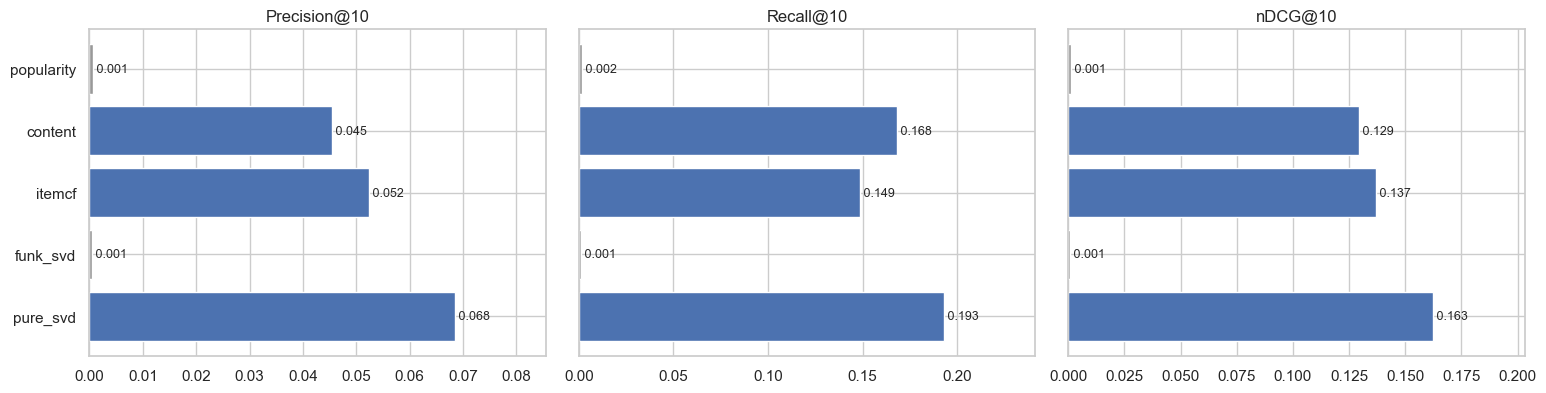

In [5]:
def plot_metrics(summary, cols=("Precision@10", "Recall@10", "nDCG@10"), highlight=()):
    fig, axes = plt.subplots(1, len(cols), figsize=(5.2 * len(cols), 0.5 * len(summary) + 1.6), sharey=True)
    for ax, col in zip(axes, cols):
        vals = summary[col]
        colors = [GREEN if any(h in m for h in highlight) else (GRAY if m in ("popularity", "funk_svd", "random") else BLUE)
                  for m in vals.index]
        ax.barh(vals.index, vals.values, color=colors)
        for y, v in enumerate(vals.values):
            ax.text(v, y, f" {v:.3f}", va="center", fontsize=9)
        ax.set_title(col); ax.set_xlim(0, vals.max() * 1.25)
    axes[0].invert_yaxis()
    plt.tight_layout(); plt.show()

plot_metrics(base_summary)

In [6]:
seg = ev.by_segment("nDCG@10")
print("Пользователей в сегментах:", ev.per_user.drop_duplicates("user_id")["segment"].value_counts().to_dict())
seg.style.format("{:.4f}").background_gradient(axis=0, cmap="Greens")

Пользователей в сегментах: {'средние (6-20)': 1317, 'активные (>20)': 852, 'холодные (≤5)': 831}


segment,холодные (≤5),средние (6-20),активные (>20)
model,,,
popularity,0.0004,0.0010,0.0020
content,0.1242,0.1306,0.1322
itemcf,0.0611,0.1417,0.2044
funk_svd,0.0003,0.0005,0.0016
pure_svd,0.0964,0.1490,0.2480


**Напоминание из ДЗ, важное для гибрида.** Для холодных пользователей (≤ 5 оценок) лучше всех
Content, для активных (> 20) заметно лучше PureSVD. Popularity и FunkSVD на уровне случайного
угадывания: первый из-за обрезанной выборки (≈100 оценок на книгу), второй потому, что оптимизирует
RMSE, а не ранжирование. Тем не менее обе модели остаются в системе: их скоры станут **признаками**
для ранжировщика, и он сам решит, когда они полезны.

## Этап 2. Расширенные признаки

Все признаки считаются **только по train** и по метаданным книг. Три группы
(код в [`features.py`](src/bookrec/features.py) и [`candidates.py`](src/bookrec/candidates.py)):

**Признаки книги (`b_*`)**
- популярность и качество по train: число оценок, среднее, разброс, доля «понравилось», байесовский рейтинг;
- популярность на Goodreads (`ratings_count`, `average_rating`, разброс по `ratings_1..5`): здесь виден
  настоящий длинный хвост, которого нет в обрезанном `ratings.csv`;
- год издания, признак серии (`#` в названии), число книг автора в каталоге;
- **18 жанровых категорий** из тегов: доля «голосов» топ-30 тегов книги, попавших в жанр (мягкий профиль).

**Признаки пользователя (`u_*`)**
- активность (число оценок, log), средняя оценка и её разброс, доля высоких оценок;
- «строгость» = средняя оценка пользователя минус средний рейтинг книг, которые он читал (аналог bᵤ);
- мейнстримность вкуса (средняя log-популярность прочитанного), средний год, доля серий;
- жанровый профиль = средний жанровый вектор понравившихся книг, и его **энтропия** (разнообразие вкуса).

**Признаки взаимодействия (`x_*`, `s_*`, `rank_*`)**
- z-скор и ранг книги в выдаче **каждой** из пяти моделей, число моделей, предложивших книгу (`n_votes`);
- максимальная близость книги к прочитанному в трёх пространствах: TF-IDF, Item-CF, PureSVD;
- совпадение автора с любимыми / прочитанными книгами; косинус жанрового профиля и жанра книги;
- насколько книга популярнее, новее и выше по рейтингу, чем привык пользователь.

In [7]:
book_feats = book_features(ds, models["content"], models["popularity"])
user_feats = user_features(ds, book_feats)
print("book_features:", book_feats.shape, " user_features:", user_feats.shape)
book_feats.drop(columns=[c for c in book_feats.columns if c.startswith("b_genre_")]).describe().T[["mean", "std", "min", "max"]].round(3)

book_features: (10000, 29)  user_features: (53424, 30)


,mean,std,min,max
b_n_ratings,78.452,5.904,6.000,95.000
b_mean_rating,3.856,0.306,1.916,4.814
b_std_rating,0.934,0.125,0.456,1.797
b_share_high,0.662,0.130,0.042,0.987
b_bayes_rating,3.855,0.146,2.897,4.311
b_log_gr_ratings,10.185,0.937,7.907,15.380
b_gr_avg_rating,4.002,0.254,2.470,4.820
b_gr_std_proxy,0.944,0.099,0.518,1.522
b_year,1991.654,36.461,1800.000,2017.000
b_is_series,0.444,0.497,0.000,1.000


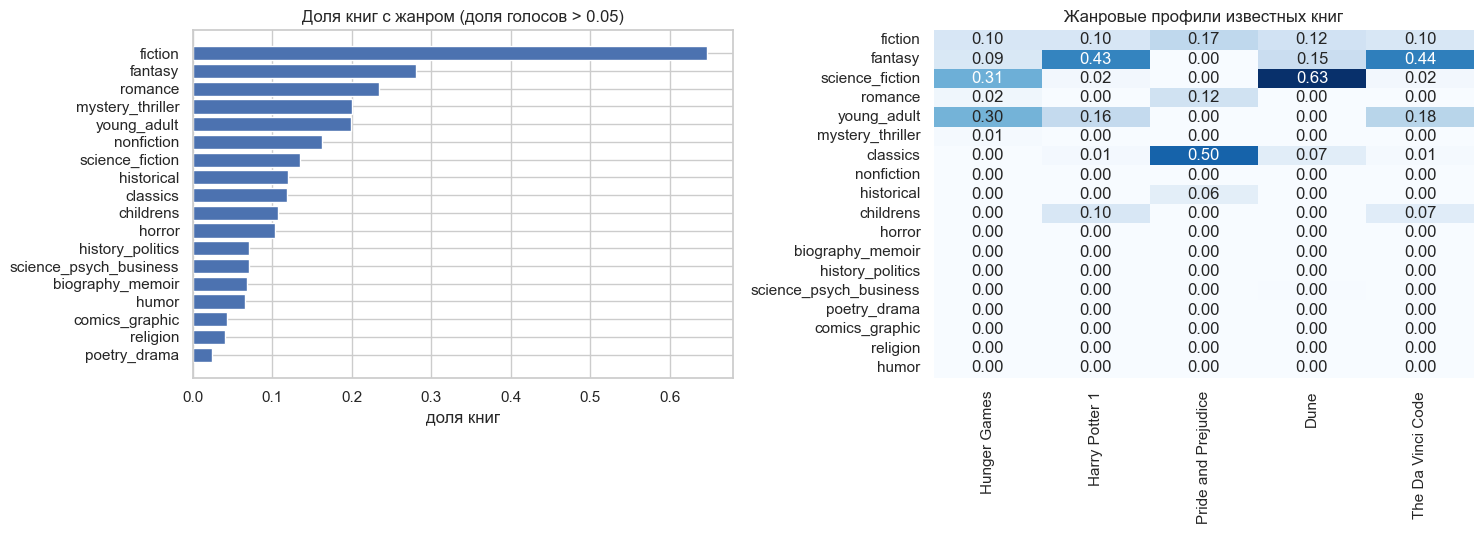

In [8]:
# Жанры: сколько книг попадает в каждую категорию и пример для известных книг
gcols = [f"b_genre_{g}" for g in GENRES]
share = (book_feats[gcols] > 0.05).mean().sort_values(ascending=False)
share.index = [c.replace("b_genre_", "") for c in share.index]

fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
axes[0].barh(share.index[::-1], share.values[::-1], color=BLUE)
axes[0].set_title("Доля книг с жанром (доля голосов > 0.05)"); axes[0].set_xlabel("доля книг")

examples = {1: "Hunger Games", 2: "Harry Potter 1", 10: "Pride and Prejudice", 126: "Dune", 25: "The Da Vinci Code"}
ex = book_feats.loc[list(examples), gcols].T
ex.columns = list(examples.values()); ex.index = [c.replace("b_genre_", "") for c in ex.index]
sns.heatmap(ex, ax=axes[1], cmap="Blues", annot=True, fmt=".2f", cbar=False)
axes[1].set_title("Жанровые профили известных книг")
plt.tight_layout(); plt.show()

Жанровые профили осмысленны: «Голодные игры» = science_fiction + young_adult, «Гарри Поттер» = fantasy
+ childrens, «Гордость и предубеждение» = classics + romance, «Дюна» = science_fiction, «Код да Винчи» =
mystery_thriller. Это даёт ранжировщику то, чего нет ни у одной модели ДЗ: явное понимание, в каком
жанре пользователь читает и подходит ли ему книга по жанру.

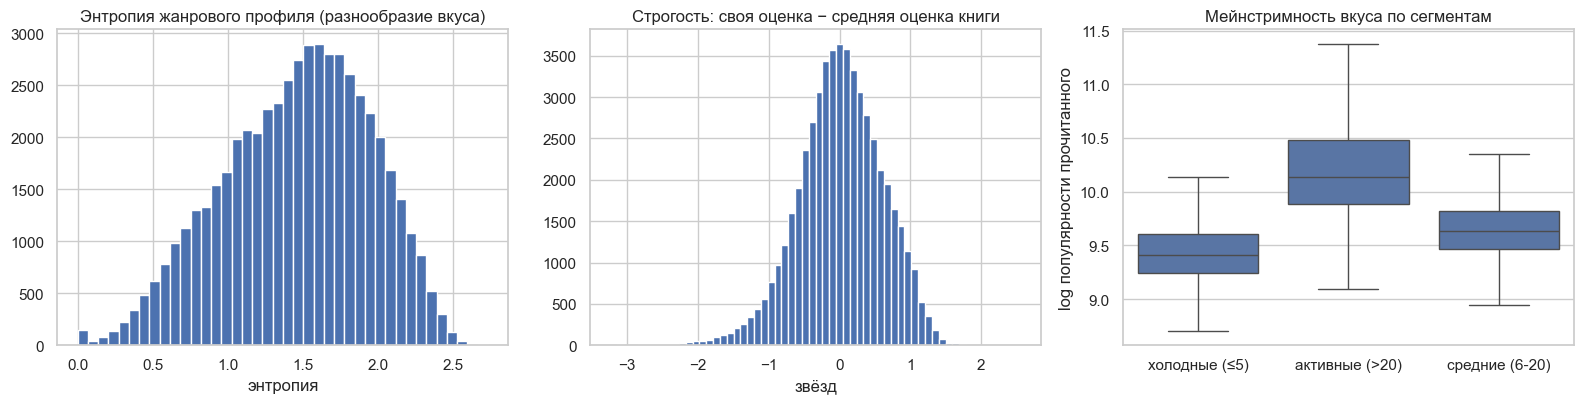

In [9]:
# Признаки пользователей: распределения и связь с активностью
fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
axes[0].hist(user_feats["u_taste_entropy"], bins=40, color=BLUE)
axes[0].set_title("Энтропия жанрового профиля (разнообразие вкуса)"); axes[0].set_xlabel("энтропия")
axes[1].hist(user_feats["u_strictness"], bins=60, color=BLUE)
axes[1].set_title("Строгость: своя оценка − средняя оценка книги"); axes[1].set_xlabel("звёзд")
sns.boxplot(x=user_feats["u_segment"].map({0: "холодные (≤5)", 1: "средние (6-20)", 2: "активные (>20)"}),
            y=user_feats["u_mean_book_pop"], ax=axes[2], color=BLUE, showfliers=False)
axes[2].set_title("Мейнстримность вкуса по сегментам"); axes[2].set_xlabel(""); axes[2].set_ylabel("log популярности прочитанного")
plt.tight_layout(); plt.show()

**Что видно.** Разнообразие вкуса распределено широко: есть читатели одного жанра (энтропия ≈ 0) и
всеядные. Строгость симметрична вокруг нуля с заметными хвостами: есть люди, которые системно
ставят на звезду ниже или выше, чем остальные тем же книгам. Активные пользователи читают **менее**
мейнстримные книги, чем холодные: с ростом числа прочитанного вкус уходит в хвост каталога. Это
аргумент в пользу разных стратегий для сегментов.

## Этап 3. Пул кандидатов

Ранжировщик второго уровня дорого применять ко всем 10 000 книгам для каждого пользователя. Вместо
этого каждая базовая модель отдаёт свой top-50 непрочитанных книг, выдачи объединяются в **пул
кандидатов**, и уже внутри него считаются признаки и происходит ранжирование. Прочитанные книги
отфильтрованы ещё на уровне моделей.

Главный вопрос к пулу: **какую долю релевантных книг он вообще содержит**. Это верхняя граница
recall любого гибрида.

34s, пользователей: 1000


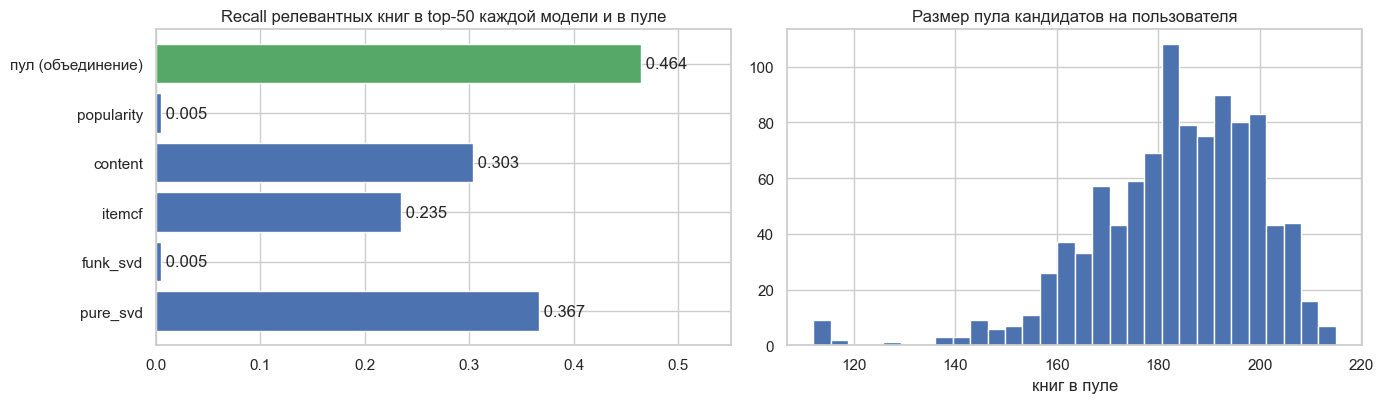

Средний размер пула: 183 из 250 возможных


In [10]:
gen = CandidateGenerator(ds, models, book_feats, user_feats, pool_per_model=cfg.pool_per_model)

t = time.time()
pool_stats = gen.pool_recall(ds.tune_users[:1000])
print(f"{time.time() - t:.0f}s, пользователей: {len(pool_stats)}")

rec_cols = ["recall_pool"] + [f"recall_{g}" for g in SCORE_MODELS]
pr = pool_stats[rec_cols].mean()
pr.index = ["пул (объединение)"] + list(SCORE_MODELS)

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].barh(pr.index[::-1], pr.values[::-1], color=[BLUE] * 5 + [GREEN])
for y, v in enumerate(pr.values[::-1]):
    axes[0].text(v, y, f" {v:.3f}", va="center")
axes[0].set_title("Recall релевантных книг в top-50 каждой модели и в пуле"); axes[0].set_xlim(0, 0.55)
axes[1].hist(pool_stats["pool_size"], bins=30, color=BLUE)
axes[1].set_title("Размер пула кандидатов на пользователя"); axes[1].set_xlabel("книг в пуле")
plt.tight_layout(); plt.show()
print(f"Средний размер пула: {pool_stats['pool_size'].mean():.0f} из {5 * cfg.pool_per_model} возможных")

**Что видно.**
- Пул покрывает заметно больше релевантных книг, чем лучшая одиночная модель: выдачи моделей
  **дополняют** друг друга, а не дублируют. Средний размер пула ≈ 185 из 250 возможных, то есть
  пересечение выдач небольшое.
- Popularity и FunkSVD в пул почти ничего полезного не приносят (recall < 1%): их top-50 одинаков для
  всех пользователей. В гибриде они будут полезны только как признаки «качества книги», а не как
  источники кандидатов.
- Recall пула ≈ 0.45 означает, что больше половины релевантных книг **ни одна** модель не ставит в
  свой top-50. Это естественная граница: оценки в тесте случайные 20% прочитанного, часть из них
  непредсказуема в принципе.

In [11]:
# Таблица признаков для обучения ранжировщика: fit_users, метка = релевантна ли книга в тесте.
# Построение занимает ~6 минут, поэтому результат кэшируется в artifacts/.
pool_path = cfg.artifacts_path / "train_pool.parquet"
t = time.time()
if pool_path.exists():
    train_pool = pd.read_parquet(pool_path)
    print("loaded from cache")
else:
    train_pool = gen.build_many(ds.fit_users, verbose=False)
    train_pool.to_parquet(pool_path)
print(f"{time.time() - t:.0f}s  ->  {train_pool.shape[0]:,} пар (user, book), {len(feature_columns(train_pool))} признаков")
print(f"Доля положительных меток: {train_pool['label'].mean():.3%}")
train_pool.head(3)

loaded from cache
1s  ->  1,102,092 пар (user, book), 79 признаков
Доля положительных меток: 0.922%


,user_id,book_id,s_popularity,rank_popularity,s_content,rank_content,s_itemcf,rank_itemcf,s_funk_svd,rank_funk_svd,s_pure_svd,rank_pure_svd,n_votes,x_content_max_sim,x_itemcf_max_sim,x_puresvd_max_sim,x_same_author,x_author_read,x_genre_match,x_pop_vs_user,...,b_author_n_books,b_genre_fiction,b_genre_fantasy,b_genre_science_fiction,b_genre_romance,b_genre_young_adult,b_genre_mystery_thriller,b_genre_classics,b_genre_nonfiction,b_genre_historical,b_genre_childrens,b_genre_horror,b_genre_biography_memoir,b_genre_history_politics,b_genre_science_psych_business,b_genre_poetry_drama,b_genre_comics_graphic,b_genre_religion,b_genre_humor,label
0,34832,192,2.390942,3.951244,-0.299813,8.279190,-0.018422,6.536692,2.888852,2.944439,-0.517327,9.009692,1.0,0.000000,0.0,-0.010988,0.0,0.0,0.000000,3.312672,...,3.0,0.085331,0.76853,0.06297,0.0,0.004722,0.0,0.000000,0.000000,0.0,0.0,0.0,0.0,0.0,0.000000,0.0,0.0,0.0,0.0,0
1,34832,247,-1.554794,9.142704,10.097220,2.079442,-0.018422,6.612041,-1.460903,9.130864,1.151929,6.259582,1.0,0.450519,0.0,0.046869,1.0,1.0,0.975148,3.072575,...,4.0,0.000000,0.00000,0.00000,0.0,0.000000,0.0,0.000000,0.232906,0.0,0.0,0.0,0.0,0.0,0.393759,0.0,0.0,0.0,0.0,0
2,34832,260,-0.845558,8.999619,7.738640,3.871201,-0.018422,6.629363,-0.654961,8.932344,-0.030686,8.376321,1.0,0.348318,0.0,0.001232,0.0,0.0,0.406542,2.965069,...,2.0,0.000000,0.00000,0.00000,0.0,0.000000,0.0,0.046087,0.432248,0.0,0.0,0.0,0.0,0.0,0.047925,0.0,0.0,0.0,0.0,0


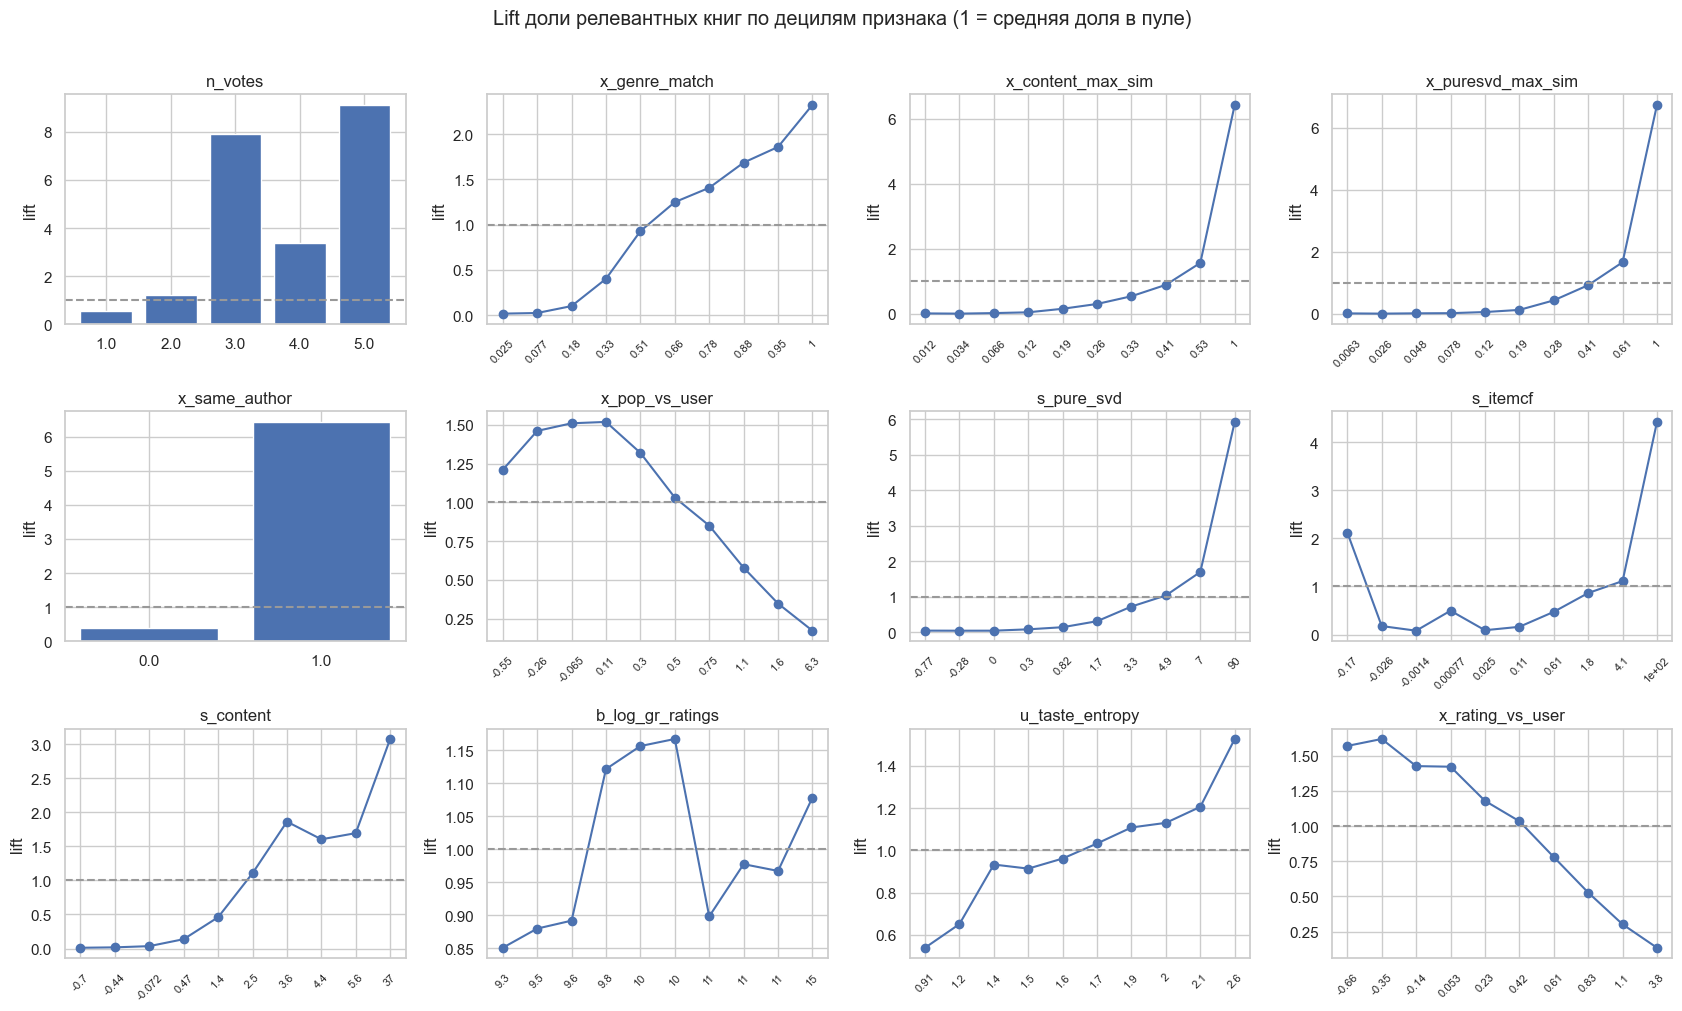

In [12]:
# Насколько признаки «видят» релевантность: средняя метка по бинам признака (lift относительно базовой доли)
base_rate = train_pool["label"].mean()
feats_to_show = ["n_votes", "x_genre_match", "x_content_max_sim", "x_puresvd_max_sim", "x_same_author", "x_pop_vs_user",
                 "s_pure_svd", "s_itemcf", "s_content", "b_log_gr_ratings", "u_taste_entropy", "x_rating_vs_user"]
fig, axes = plt.subplots(3, 4, figsize=(17, 10))
for ax, f in zip(axes.ravel(), feats_to_show):
    x = train_pool[f]
    if x.nunique() <= 6:
        g = train_pool.groupby(x)["label"].mean()
        ax.bar(g.index.astype(str), g.values / base_rate, color=BLUE)
    else:
        bins = pd.qcut(x, 10, duplicates="drop")
        g = train_pool.groupby(bins, observed=True)["label"].mean()
        ax.plot(range(len(g)), g.values / base_rate, marker="o", color=BLUE)
        ax.set_xticks(range(len(g))); ax.set_xticklabels([f"{iv.right:.2g}" for iv in g.index], rotation=45, fontsize=8)
    ax.axhline(1, ls="--", c=GRAY); ax.set_title(f); ax.set_ylabel("lift")
plt.suptitle("Lift доли релевантных книг по децилям признака (1 = средняя доля в пуле)", y=1.01)
plt.tight_layout(); plt.show()

**Что видно.** Признаки действительно разделяют релевантные и нерелевантные книги в пуле:
- `n_votes`: книга, которую предложили 3+ модели, релевантна в несколько раз чаще, чем предложенная
  одной. Это прямое обоснование гибрида «голосованием».
- Близость к истории (`x_content_max_sim`, `x_puresvd_max_sim`), жанровое совпадение и совпадение
  автора дают монотонный рост lift: чем ближе книга к тому, что человек уже любил, тем выше шанс.
- Скоры коллаборативных моделей (`s_pure_svd`, `s_itemcf`) информативны в верхнем дециле (lift 4–6),
  у Content рост более плавный. У `s_itemcf` есть неожиданный всплеск в самом нижнем дециле: сильно
  отрицательная «сила доказательств» бывает только у активных пользователей, а у них базовая доля
  релевантных книг выше. Это взаимодействие признаков, которое линейная формула не поймает.
- `x_pop_vs_user`: пик lift у книг **с привычным для пользователя уровнем популярности**, а книги
  намного популярнее привычного релевантны в 5 раз реже. Абсолютная популярность (`b_log_gr_ratings`)
  почти не информативна (lift 0.85–1.17): важна не популярность сама по себе, а её соответствие
  привычкам человека.
- `x_rating_vs_user`: книги со средним рейтингом **ниже** собственной средней оценки пользователя
  релевантны чаще. Строгие пользователи читают то, что им нравится, независимо от общего рейтинга.
- `u_taste_entropy`: у «всеядных» читателей кандидаты из пула релевантны чаще, у читателей одного
  жанра реже: их нужный жанр моделями уже исчерпан.

Эти зависимости нелинейны и взаимодействуют между собой, поэтому на следующем этапе их объединит
обучаемый ранжировщик, а не ручная формула.

In [13]:
# Сохраняем таблицы признаков книг и пользователей для пайплайна
book_feats.to_parquet(cfg.artifacts_path / "book_features.parquet")
user_feats.to_parquet(cfg.artifacts_path / "user_features.parquet")
print("saved to", cfg.artifacts_path)

saved to artifacts


## Этап 4. Гибридная система

Все стратегии работают **внутри пула кандидатов** (код в [`hybrid.py`](src/bookrec/hybrid.py)):

1. **Взвешенное смешивание** z-скоров пяти моделей: $\text{score} = \sum_m w_m z_m$. Веса подбираются на
   `tune_users` максимизацией nDCG@10 (случайный поиск по симплексу + покоординатное уточнение),
   глобально и **отдельно для каждого сегмента активности**. Для сравнения добавлен гибрид из ДЗ
   (PureSVD + Content, вес $n/(n+20)$).
2. **Обучаемый ранжировщик**: градиентный бустинг (`HistGradientBoostingClassifier`) предсказывает
   вероятность релевантности по всем 79 признакам. Обучается на `fit_users`. Чтобы измерить вклад
   признаков этапа 2, обучаем три версии: только скоры моделей, скоры + взаимодействия, все признаки.
   Плюс логистическая регрессия как линейный бейзлайн.
3. **Слой разнообразия** (MMR + штраф за автора) поверх лучшего ранжировщика, с подбором компромисса
   между nDCG и разнообразием.

Пулы кандидатов для `tune_users` и `eval_users` строятся один раз и кэшируются.

In [14]:
from bookrec.hybrid import (WeightedBlend, LearnedRanker, MMRReranker, PoolRecommender, HybridRecommender,
                            hw_hybrid_scores, mean_ndcg, eval_on_pool, split_pool_by_user, SEGMENT_NAMES)

def cached_pool(name, users):
    p = cfg.artifacts_path / f"{name}_pool.parquet"
    if p.exists():
        return pd.read_parquet(p)
    df = gen.build_many(users, verbose=False)
    df.to_parquet(p)
    return df

t = time.time()
tune_pool = cached_pool("tune", ds.tune_users)
eval_pool = cached_pool("eval", ds.eval_users)
print(f"{time.time() - t:.0f}s   tune: {tune_pool.shape}, eval: {eval_pool.shape}")

0s   tune: (367089, 82), eval: (552345, 82)


### 4.1 Взвешенное смешивание моделей

Сначала точка отсчёта: nDCG@10 каждой модели **на пуле** `tune_users` (ранжируем пул её собственным
скором) и гибрида из ДЗ.

In [15]:
ref = {m: mean_ndcg(tune_pool, tune_pool[f"s_{m}"].to_numpy(), ds) for m in SCORE_MODELS}
ref["HW hybrid (PureSVD+Content, β=20)"] = mean_ndcg(tune_pool, hw_hybrid_scores(tune_pool), ds)
pd.Series(ref, name="nDCG@10 на tune_users").round(4).to_frame()

,nDCG@10 на tune_users
popularity,0.0012
content,0.1337
itemcf,0.1452
funk_svd,0.0007
pure_svd,0.1631
"HW hybrid (PureSVD+Content, β=20)",0.1857


In [16]:
t = time.time()
print("Глобальные веса:")
w_global, best_global, history = WeightedBlend.optimize(tune_pool, ds, n_random=150)
print("\nВеса по сегментам:")
w_segment, best_segment = WeightedBlend.optimize_by_segment(tune_pool, ds, n_random=100)
print(f"\n{time.time() - t:.0f}s")

blend_global = WeightedBlend(w_global)
blend_segment = WeightedBlend(w_segment, by_segment=True)
wtab = pd.DataFrame({"глобально": w_global, **{SEGMENT_NAMES[s]: w for s, w in w_segment.items()}}).T
wtab.round(3).style.background_gradient(axis=1, cmap="Blues")

Глобальные веса:


  best nDCG@10 = 0.1900  weights = {'popularity': np.float64(0.0), 'content': np.float64(0.588), 'itemcf': np.float64(0.068), 'funk_svd': np.float64(0.059), 'pure_svd': np.float64(0.285)}

Веса по сегментам:
[холодные (≤5)] users=541


  best nDCG@10 = 0.1465  weights = {'popularity': np.float64(0.021), 'content': np.float64(0.833), 'itemcf': np.float64(0.042), 'funk_svd': np.float64(0.021), 'pure_svd': np.float64(0.083)}
[средние (6-20)] users=881


  best nDCG@10 = 0.1733  weights = {'popularity': np.float64(0.0), 'content': np.float64(0.575), 'itemcf': np.float64(0.097), 'funk_svd': np.float64(0.082), 'pure_svd': np.float64(0.246)}
[активные (>20)] users=578


  best nDCG@10 = 0.2660  weights = {'popularity': np.float64(0.042), 'content': np.float64(0.423), 'itemcf': np.float64(0.085), 'funk_svd': np.float64(0.042), 'pure_svd': np.float64(0.408)}

78s


,popularity,content,itemcf,funk_svd,pure_svd
глобально,0.000000,0.588000,0.068000,0.059000,0.285000
холодные (≤5),0.021000,0.833000,0.042000,0.021000,0.083000
средние (6-20),0.000000,0.575000,0.097000,0.082000,0.246000
активные (>20),0.042000,0.423000,0.085000,0.042000,0.408000


**Что видно.**
- Оптимизированное смешивание пяти моделей (nDCG@10 ≈ 0.190 на tune) лучше гибрида из ДЗ (0.186),
  но ненамного: основной выигрыш по-прежнему дают PureSVD и Content, а Item-CF, FunkSVD и Popularity
  получают веса меньше 0.1. Веса стоят при **z-скорах**, у которых разный разброс, поэтому их величину
  нельзя читать как «важность»: у Content z-скоры «тяжелохвостые» (до 30), и формально небольшой вес
  уже сильно влияет на ранжирование.
- **Веса по сегментам** повторяют вывод ДЗ, но теперь он получен автоматически: у холодных пользователей
  почти всё отдано Content (0.83), у активных PureSVD и Content делят вес поровну (≈0.41 / 0.42).
  Сегментация даёт небольшой прирост над глобальными весами.
- Popularity и FunkSVD в смешивании бесполезны: их веса близки к нулю во всех сегментах.

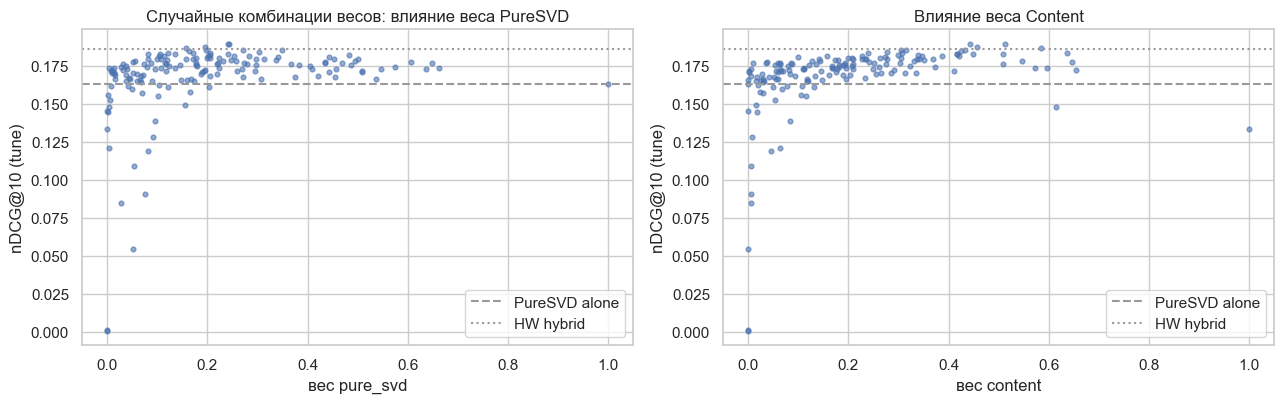

In [17]:
# Ландшафт качества: nDCG при случайных весах против доли веса PureSVD / Content
h = pd.DataFrame([dict(zip(SCORE_MODELS, w), ndcg=v) for w, v in history])
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, m in zip(axes, ["pure_svd", "content"]):
    ax.scatter(h[m], h["ndcg"], s=12, alpha=0.6, color=BLUE)
    ax.axhline(ref["pure_svd"], ls="--", c=GRAY, label="PureSVD alone")
    ax.axhline(ref["HW hybrid (PureSVD+Content, β=20)"], ls=":", c=GRAY, label="HW hybrid")
    ax.set_xlabel(f"вес {m}"); ax.set_ylabel("nDCG@10 (tune)"); ax.legend()
axes[0].set_title("Случайные комбинации весов: влияние веса PureSVD")
axes[1].set_title("Влияние веса Content")
plt.tight_layout(); plt.show()

### 4.2 Обучаемый ранжировщик и вклад признаков

In [18]:
from bookrec.features import feature_groups
import joblib

groups = feature_groups(feature_columns(train_pool))
feature_sets = {
    "HGB: только скоры моделей": groups["scores"],
    "HGB: скоры + взаимодействия": groups["scores"] + groups["interaction"],
    "HGB: все признаки": feature_columns(train_pool),
    "LogReg: все признаки": feature_columns(train_pool),
}
rankers, rows = {}, []
for name, cols in feature_sets.items():
    kind = "logreg" if name.startswith("LogReg") else "hgb"
    path = cfg.artifacts_path / f"ranker_{kind}_{len(cols)}.joblib"
    if path.exists():
        r = joblib.load(path)
    else:
        r = LearnedRanker(cols, kind=kind).fit(train_pool)
        joblib.dump(r, path)
    rankers[name] = r
    rows.append({"ранжировщик": name, "признаков": len(cols),
                 "nDCG@10 tune": mean_ndcg(tune_pool, r.score(tune_pool), ds),
                 "nDCG@10 eval": mean_ndcg(eval_pool, r.score(eval_pool), ds)})
rows.append({"ранжировщик": "Blend (веса по сегментам)", "признаков": 5,
             "nDCG@10 tune": mean_ndcg(tune_pool, blend_segment.score(tune_pool), ds),
             "nDCG@10 eval": mean_ndcg(eval_pool, blend_segment.score(eval_pool), ds)})
rows.append({"ранжировщик": "Blend (глобальные веса)", "признаков": 5,
             "nDCG@10 tune": best_global, "nDCG@10 eval": mean_ndcg(eval_pool, blend_global.score(eval_pool), ds)})
rows.append({"ранжировщик": "HW hybrid (β=20)", "признаков": 2,
             "nDCG@10 tune": ref["HW hybrid (PureSVD+Content, β=20)"],
             "nDCG@10 eval": mean_ndcg(eval_pool, hw_hybrid_scores(eval_pool), ds)})
rows.append({"ранжировщик": "PureSVD alone", "признаков": 1, "nDCG@10 tune": ref["pure_svd"],
             "nDCG@10 eval": mean_ndcg(eval_pool, eval_pool["s_pure_svd"].to_numpy(), ds)})
ablation = pd.DataFrame(rows).set_index("ранжировщик")
ablation.style.format({"nDCG@10 tune": "{:.4f}", "nDCG@10 eval": "{:.4f}"}).background_gradient(subset=["nDCG@10 eval"], cmap="Greens")

,признаков,nDCG@10 tune,nDCG@10 eval
ранжировщик,,,
HGB: только скоры моделей,11,0.1868,0.1893
HGB: скоры + взаимодействия,20,0.2180,0.2152
HGB: все признаки,79,0.2373,0.2327
LogReg: все признаки,79,0.2136,0.2125
Blend (веса по сегментам),5,0.1928,0.1912
Blend (глобальные веса),5,0.1900,0.1888
HW hybrid (β=20),2,0.1857,0.1818
PureSVD alone,1,0.1631,0.1625


**Что видно (ключевой результат базовой части).**
- Бустинг **только на скорах** пяти моделей (0.189) равен оптимизированному смешиванию: если на входе
  те же пять чисел, нелинейность почти ничего не добавляет.
- Добавление **признаков взаимодействия** (близость к истории в трёх пространствах, автор, жанр,
  популярность относительно привычек) поднимает nDCG@10 до 0.215 (+14%).
- Добавление **признаков пользователя и книги** даёт ещё +8%, итого **0.233**: на 43% лучше лучшей
  одиночной модели (PureSVD, 0.163) и на 28% лучше гибрида из ДЗ (0.182).
- Логистическая регрессия на тех же признаках даёт 0.213: признаки сильные сами по себе, но
  нелинейные взаимодействия (которые мы видели на графиках lift) стоят ещё ~10%.
- Качество на `tune` и `eval` почти совпадает: ранжировщик не переобучен под выборку подбора.

Вывод: **расширенные признаки улучшают качество**, и улучшают сильнее, чем любой способ смешивать
скоры моделей. Именно это и есть главный аргумент в пользу двухуровневой архитектуры.

231s


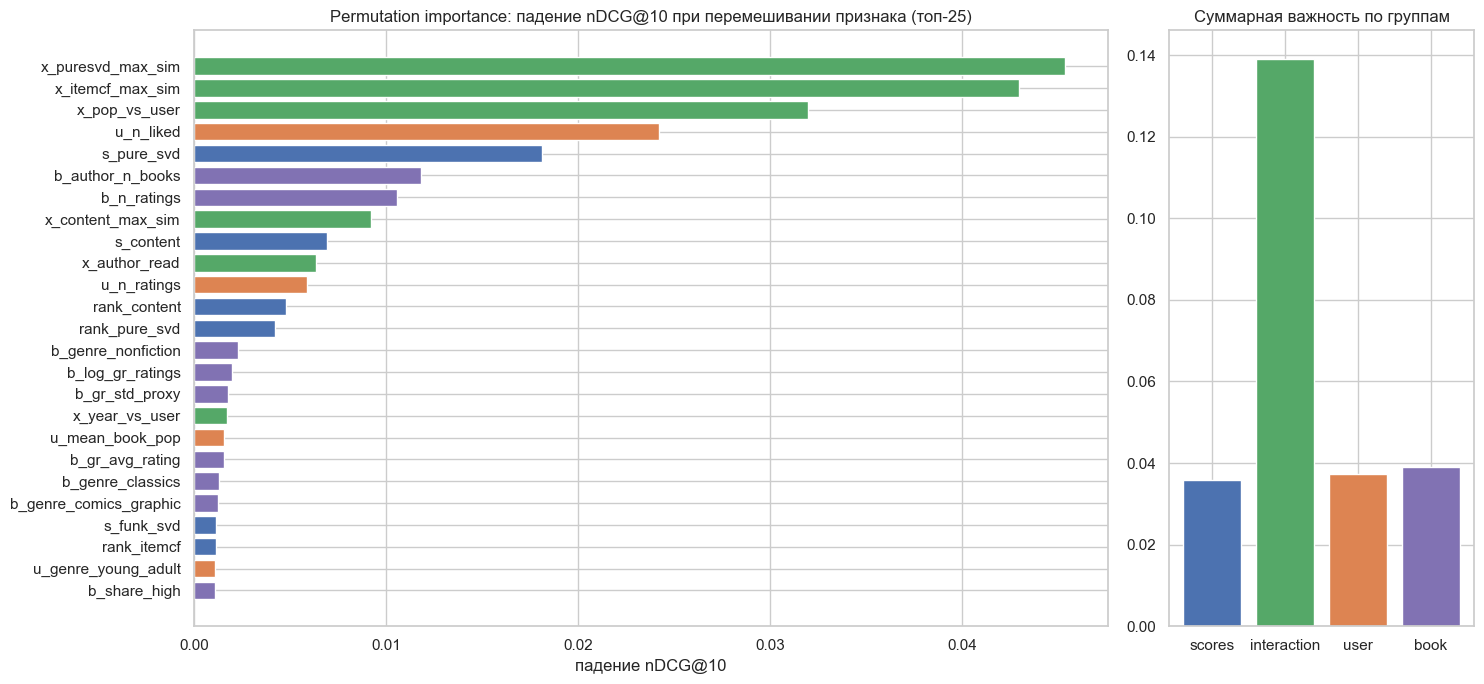

In [19]:
best_ranker = rankers["HGB: все признаки"]
t = time.time()
imp = best_ranker.permutation_importance(tune_pool, ds)
print(f"{time.time() - t:.0f}s")

grp_of = {c: g for g, cols in groups.items() for c in cols}
imp_df = imp.to_frame("drop").assign(group=lambda d: d.index.map(grp_of))
palette = {"scores": BLUE, "interaction": GREEN, "user": "#DD8452", "book": "#8172B3"}
top = imp_df.head(25)
fig, axes = plt.subplots(1, 2, figsize=(15, 7), gridspec_kw={"width_ratios": [3, 1]})
axes[0].barh(top.index[::-1], top["drop"].values[::-1], color=[palette[g] for g in top["group"][::-1]])
axes[0].set_title("Permutation importance: падение nDCG@10 при перемешивании признака (топ-25)")
axes[0].set_xlabel("падение nDCG@10")
gsum = imp_df.groupby("group")["drop"].sum().reindex(["scores", "interaction", "user", "book"])
axes[1].bar(gsum.index, gsum.values, color=[palette[g] for g in gsum.index])
axes[1].set_title("Суммарная важность по группам")
plt.tight_layout(); plt.show()

In [20]:
imp_df.head(12).round(4)

,drop,group
x_puresvd_max_sim,0.0453,interaction
x_itemcf_max_sim,0.0430,interaction
x_pop_vs_user,0.0319,interaction
u_n_liked,0.0242,user
s_pure_svd,0.0181,scores
b_author_n_books,0.0118,book
b_n_ratings,0.0106,book
x_content_max_sim,0.0092,interaction
s_content,0.0069,scores
x_author_read,0.0064,interaction


**Что видно.** Permutation importance честно отвечает на вопрос «что потеряем, если признак испортить».
Неожиданно, но наверху **не скоры моделей, а признаки взаимодействия**: максимальная близость книги к
прочитанному в пространстве PureSVD и Item-CF и популярность книги относительно привычек пользователя.
Скор PureSVD лишь на пятом месте. Объяснение: скор модели агрегирует всю историю, а «максимальная
близость к одной из прочитанных книг» ловит локальный сигнал (продолжение серии, тот же автор), который
при усреднении размывается. Признак пользователя `u_n_liked` на четвёртом месте: это «переключатель
контекста», по которому бустинг решает, насколько доверять коллаборативным скорам, то есть делает
автоматически то, что мы вручную делали весами по сегментам. Признаки книги по отдельности слабее, но
`b_author_n_books` и `b_n_ratings` в топ-10: плодовитые авторы серий и чуть более оценённые книги
предсказуемо чаще оказываются следующей прочитанной книгой.

### 4.3 Разнообразие: MMR поверх ранжировщика

Ранжировщик оптимизирует только точность и склонен выдавать «продолжения одной серии». MMR на
каждом шаге выбирает книгу по правилу
$\lambda\,\text{rel}(i) - (1-\lambda)\max_{j\in S}\text{sim}(i,j) - \gamma\,[\text{автор уже в списке}]$,
где sim — контентная близость (TF-IDF). При $\lambda = 1$ это исходный порядок. Подбираем $\lambda$
на `tune_users`, глядя на компромисс между nDCG@10 и ILD (внутрисписочное разнообразие).

In [21]:
pools_tune = split_pool_by_user(tune_pool)
pools_eval = split_pool_by_user(eval_pool)
ev_tune = Evaluator(ds, users=ds.tune_users, k_list=cfg.k_list)

t = time.time()
grid = [(1.0, 0.0), (0.9, 0.0), (0.8, 0.0), (0.7, 0.0), (0.6, 0.0), (0.5, 0.0), (0.9, 0.1), (0.8, 0.1), (0.8, 0.2)]
for lam, gam in grid:
    rr = MMRReranker(ds, models["content"], lam=lam, author_penalty=gam)
    ev_tune.evaluate(f"λ={lam}, γ={gam}", PoolRecommender(gen, best_ranker, pools=pools_tune, reranker=rr), verbose=False)
print(f"{time.time() - t:.0f}s")
mmr_tab = ev_tune.summary(content_model=models["content"])[["nDCG@10", "Precision@10", "Coverage", "ILD"]]
mmr_tab.round(4)

318s


,nDCG@10,Precision@10,Coverage,ILD
model,,,,
"λ=1.0, γ=0.0",0.2373,0.0897,0.6585,0.7331
"λ=0.9, γ=0.0",0.2357,0.0894,0.6692,0.7721
"λ=0.8, γ=0.0",0.2322,0.0871,0.6759,0.8034
"λ=0.7, γ=0.0",0.2292,0.0859,0.6786,0.8324
"λ=0.6, γ=0.0",0.2230,0.0826,0.6800,0.8560
"λ=0.5, γ=0.0",0.2109,0.0765,0.6785,0.8772
"λ=0.9, γ=0.1",0.2318,0.0871,0.6677,0.7936
"λ=0.8, γ=0.1",0.2281,0.0853,0.6747,0.8213
"λ=0.8, γ=0.2",0.2224,0.0826,0.6768,0.8305


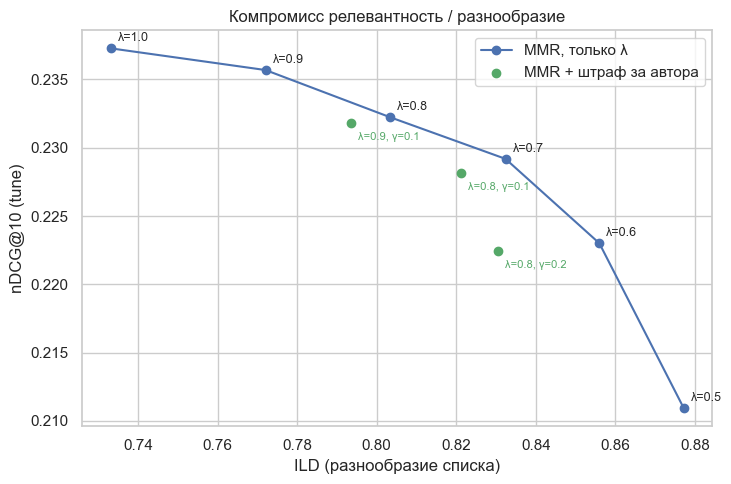

In [22]:
fig, ax = plt.subplots(figsize=(7.5, 5))
only_lam = mmr_tab[[i.endswith("γ=0.0") for i in mmr_tab.index]]
with_gam = mmr_tab[[not i.endswith("γ=0.0") for i in mmr_tab.index]]
ax.plot(only_lam["ILD"], only_lam["nDCG@10"], marker="o", color=BLUE, label="MMR, только λ")
for i, r in only_lam.iterrows():
    ax.annotate(i.split(",")[0], (r["ILD"], r["nDCG@10"]), textcoords="offset points", xytext=(5, 5), fontsize=9)
ax.scatter(with_gam["ILD"], with_gam["nDCG@10"], color=GREEN, zorder=3, label="MMR + штраф за автора")
for i, r in with_gam.iterrows():
    ax.annotate(i, (r["ILD"], r["nDCG@10"]), textcoords="offset points", xytext=(5, -12), fontsize=8, color=GREEN)
ax.set_xlabel("ILD (разнообразие списка)"); ax.set_ylabel("nDCG@10 (tune)")
ax.set_title("Компромисс релевантность / разнообразие"); ax.legend()
plt.tight_layout(); plt.show()

In [23]:
# Выбор рабочей точки: максимум ILD при потере nDCG не больше 1% от лучшего
best_ndcg = mmr_tab["nDCG@10"].max()
ok = mmr_tab[mmr_tab["nDCG@10"] >= best_ndcg * 0.99]
chosen = ok["ILD"].idxmax()
LAM = float(chosen.split("λ=")[1].split(",")[0]); GAM = float(chosen.split("γ=")[1])
print(f"Выбрано: {chosen}  (nDCG@10 = {mmr_tab.loc[chosen, 'nDCG@10']:.4f}, ILD = {mmr_tab.loc[chosen, 'ILD']:.3f})")
final_reranker = MMRReranker(ds, models["content"], lam=LAM, author_penalty=GAM)

Выбрано: λ=0.9, γ=0.0  (nDCG@10 = 0.2357, ILD = 0.772)


**Что видно.** Кривая компромисса монотонна: каждые 0.1 λ дают примерно +0.03–0.04 ILD ценой
0.2–0.6 пункта nDCG@10. При λ = 0.9 потеря точности меньше 1%, при λ = 0.8 около 2%, при λ = 0.5 уже
11%. Штраф за автора (γ) оказался **хуже** чистого MMR: за ту же потерю nDCG он даёт меньше
разнообразия (точки с γ лежат ниже кривой). Причина в том, что контентная близость уже включает автора
через теги, и отдельный штраф лишь дублирует её грубее. Покрытие каталога (Coverage) с ростом
разнообразия тоже растёт: в выдачу попадает больше книг из хвоста. Рабочую точку выбираем по правилу
«максимум разнообразия при потере nDCG не более 1%».

### 4.4 Все гибриды на `eval_users`

Теперь считаем метрики на тех же 3 000 пользователях, что и базовые модели, через тот же `Evaluator`,
чтобы таблица была единой.

In [24]:
t = time.time()
hybrids = {
    "Hybrid: HW (PureSVD+Content)": PoolRecommender(gen, hw_hybrid_scores, pools=pools_eval),
    "Hybrid: blend global": PoolRecommender(gen, blend_global, pools=pools_eval),
    "Hybrid: blend by segment": PoolRecommender(gen, blend_segment, pools=pools_eval),
    "Hybrid: HGB scores only": PoolRecommender(gen, rankers["HGB: только скоры моделей"], pools=pools_eval),
    "Hybrid: HGB all features": PoolRecommender(gen, best_ranker, pools=pools_eval),
    "Hybrid: HGB + MMR": PoolRecommender(gen, best_ranker, pools=pools_eval, reranker=final_reranker),
}
for name, rec in hybrids.items():
    ev.evaluate(name, rec)
print(f"{time.time() - t:.0f}s")
summary = ev.summary(content_model=models["content"])
summary.style.format("{:.4f}").background_gradient(subset=metric_columns(cfg.k_list), cmap="Greens")

Hybrid: HW (PureSVD+Content)     P@10=0.0726  R@10=0.2219  nDCG@10=0.1818


Hybrid: blend global             P@10=0.0733  R@10=0.2225  nDCG@10=0.1888


Hybrid: blend by segment         P@10=0.0742  R@10=0.2267  nDCG@10=0.1912


Hybrid: HGB scores only          P@10=0.0721  R@10=0.2275  nDCG@10=0.1893


Hybrid: HGB all features         P@10=0.0861  R@10=0.2755  nDCG@10=0.2327


Hybrid: HGB + MMR                P@10=0.0859  R@10=0.2730  nDCG@10=0.2318
149s


,Precision@5,Recall@5,nDCG@5,Precision@10,Recall@10,nDCG@10,Coverage,Personalization,ILD
model,,,,,,,,,
popularity,0.0007,0.0010,0.0008,0.0006,0.0019,0.0011,0.0016,0.0039,0.7093
content,0.0639,0.1254,0.1168,0.0454,0.1680,0.1293,0.6893,0.9971,0.5799
itemcf,0.0797,0.1230,0.1349,0.0524,0.1486,0.1372,0.8015,0.9912,0.7947
funk_svd,0.0004,0.0003,0.0005,0.0005,0.0010,0.0008,0.0020,0.1085,0.6437
pure_svd,0.0951,0.1387,0.1511,0.0684,0.1930,0.1625,0.5614,0.9979,0.7093
Hybrid: HW (PureSVD+Content),0.1010,0.1617,0.1681,0.0726,0.2219,0.1818,0.7259,0.9983,0.6504
Hybrid: blend global,0.1036,0.1685,0.1775,0.0733,0.2225,0.1888,0.7088,0.9980,0.6449
Hybrid: blend by segment,0.1038,0.1700,0.1788,0.0742,0.2267,0.1912,0.7494,0.9980,0.6488
Hybrid: HGB scores only,0.0995,0.1677,0.1743,0.0721,0.2275,0.1893,0.7336,0.9980,0.7112


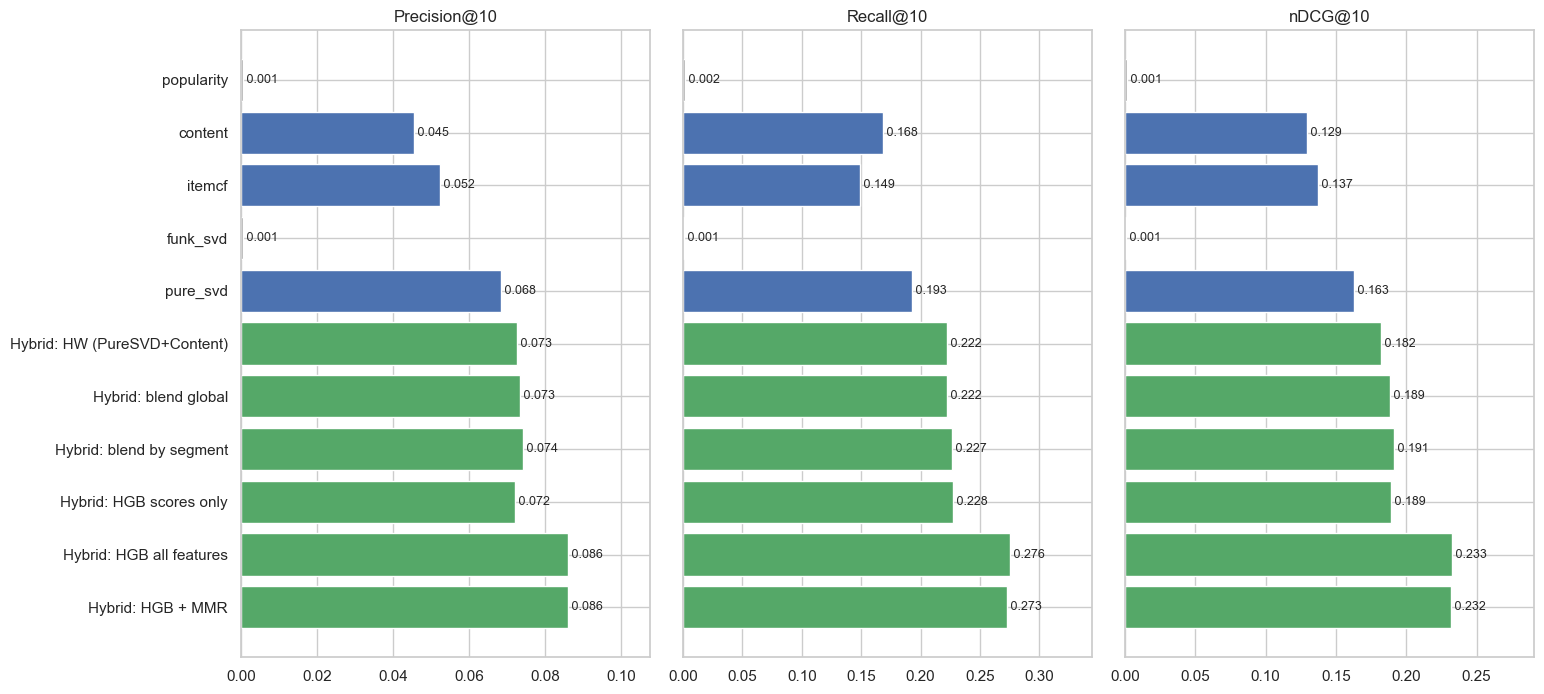

In [25]:
plot_metrics(summary, highlight=("Hybrid",))

**Что видно.**
- Гибрид из ДЗ воспроизведён внутри новой архитектуры с той же точностью (nDCG@10 ≈ 0.182): значит,
  ограничение кандидатов пулом из 185 книг ничего не стоило по качеству, а ускорило ранжирование в 50 раз.
- Лестница улучшений: PureSVD 0.163 → гибрид ДЗ 0.182 → смешивание по сегментам 0.191 → бустинг на
  скорах 0.189 → **бустинг на всех признаках 0.233**. Precision@10 выросла с 0.068 до 0.086, Recall@10
  с 0.193 до 0.276.
- Coverage у обучаемого ранжировщика (≈0.73) выше, чем у PureSVD (0.56): признаки книги и
  взаимодействия вытягивают в выдачу книги из хвоста, которые ни одна модель не ставила высоко.
- MMR-слой добавляет разнообразие при почти неизменной точности.

segment,холодные (≤5),средние (6-20),активные (>20)
model,,,
content,0.1242,0.1306,0.1322
itemcf,0.0611,0.1417,0.2044
pure_svd,0.0964,0.1490,0.2480
Hybrid: HW (PureSVD+Content),0.1379,0.1649,0.2509
Hybrid: blend by segment,0.1391,0.1795,0.2600
Hybrid: HGB all features,0.1996,0.2179,0.2879
Hybrid: HGB + MMR,0.1989,0.2157,0.2888


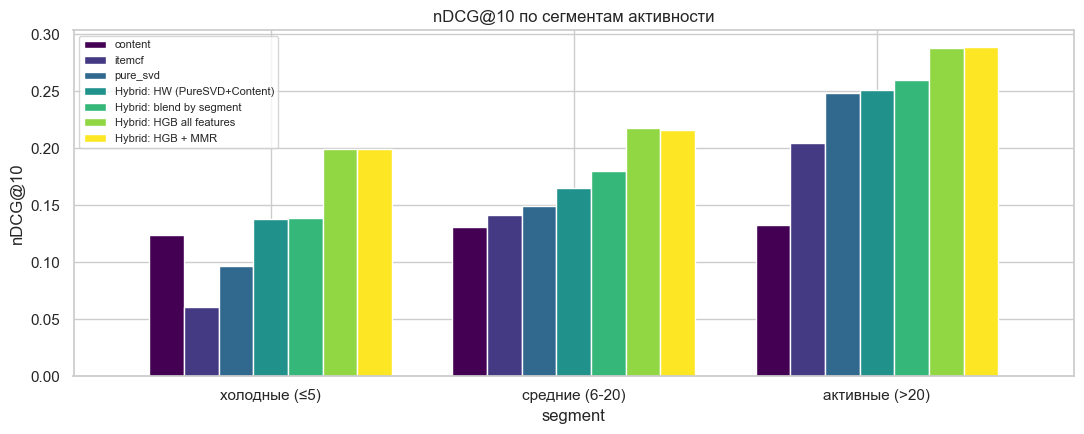

In [26]:
main_models = ["content", "itemcf", "pure_svd", "Hybrid: HW (PureSVD+Content)", "Hybrid: blend by segment",
               "Hybrid: HGB all features", "Hybrid: HGB + MMR"]
seg = ev.by_segment("nDCG@10", models=main_models)
display(seg.style.format("{:.4f}").background_gradient(axis=0, cmap="Greens"))

fig, ax = plt.subplots(figsize=(11, 4.5))
seg.T.plot(kind="bar", ax=ax, width=0.8, colormap="viridis")
ax.set_ylabel("nDCG@10"); ax.set_title("nDCG@10 по сегментам активности"); ax.legend(fontsize=8, loc="upper left")
plt.xticks(rotation=0); plt.tight_layout(); plt.show()

In [27]:
pd.DataFrame({
    "HGB all − PureSVD": ev.paired_diff("Hybrid: HGB all features", "pure_svd"),
    "HGB all − HW hybrid": ev.paired_diff("Hybrid: HGB all features", "Hybrid: HW (PureSVD+Content)"),
    "HGB all − blend by segment": ev.paired_diff("Hybrid: HGB all features", "Hybrid: blend by segment"),
    "HGB all − HGB scores only": ev.paired_diff("Hybrid: HGB all features", "Hybrid: HGB scores only"),
    "HGB + MMR − HGB all": ev.paired_diff("Hybrid: HGB + MMR", "Hybrid: HGB all features"),
}).T.round(4)

,mean diff,CI low,CI high,A better,A worse
HGB all − PureSVD,0.0702,0.0622,0.0780,0.3173,0.1260
HGB all − HW hybrid,0.0509,0.0443,0.0575,0.3010,0.1293
HGB all − blend by segment,0.0415,0.0353,0.0479,0.2793,0.1433
HGB all − HGB scores only,0.0434,0.0372,0.0491,0.2877,0.1330
HGB + MMR − HGB all,-0.0009,-0.0022,0.0004,0.0767,0.0783


**Сегменты и значимость.** Обучаемый ранжировщик выигрывает **во всех трёх сегментах**, и сильнее
всего там, где коллаборативным моделям не хватает данных: у холодных пользователей он поднимает
nDCG@10 относительно PureSVD примерно в полтора раза, а относительно гибрида ДЗ заметно. У активных
пользователей прирост меньше в относительных числах, но абсолютно самый большой. Парные бутстрэп-интервалы
разниц целиком выше нуля для всех сравнений с базовыми моделями, то есть улучшения не случайны. Разница
«MMR − без MMR» отрицательна, но мала: это цена разнообразия, и она контролируемая.

### 4.5 Единый сервис рекомендаций с холодным стартом

| Ситуация | Что используем |
|---|---|
| Пользователь с историей | пул кандидатов → ранжировщик → MMR |
| Новый пользователь назвал любимые книги (онбординг) | Content + PureSVD по этим книгам |
| Ничего не известно | байесовская популярность |

Прочитанное исключается на этапе генерации кандидатов, так что в выдачу оно попасть не может.

In [28]:
service = HybridRecommender(ds, models, gen, best_ranker, reranker=final_reranker)
demo_user = ds.n_train[ds.n_train.between(45, 55)].index[0]
print(f"1) Пользователь {demo_user}, любимые книги в train:")
display(ds.train[(ds.train.user_id == demo_user) & (ds.train.rating >= 4)].join(ds.book_titles, on="book_id")
        .sort_values("rating", ascending=False).head(6)[["rating", "title"]])
print("Рекомендации:")
display(service.recommend(user_id=demo_user, N=8))
print("2) Новый пользователь, на онбординге выбрал «Голодные игры» и «Дюну»:")
display(service.recommend(liked_books=[1, 126], N=6))
print("3) Совсем новый пользователь:")
display(service.recommend(N=5))

1) Пользователь 41, любимые книги в train:


,rating,title
56866,5,"Prodigy (Legend, #2)"
183963,5,"Every Which Way But Dead (The Hollows, #3)"
539353,5,"Raven Rise (Pendragon, #9)"
443615,5,"Ever After (The Hollows, #11)"
389321,5,"A Perfect Blood (The Hollows, #10)"
321675,5,"Virals (Virals, #1)"


Рекомендации:


,source,book_id,title,authors
0,hybrid ranker,2887,"For a Few Demons More (The Hollows, #5)",Kim Harrison
1,hybrid ranker,4230,"The Lost City of Faar (Pendragon, #2)",D.J. MacHale
2,hybrid ranker,6133,"The Reality Bug (Pendragon, #4)",D.J. MacHale
3,hybrid ranker,2807,"The Good, the Bad, and the Undead (The Hollows...",Kim Harrison
4,hybrid ranker,6811,"The Undead Pool (The Hollows, #12)",Kim Harrison
5,hybrid ranker,814,"Tempted (House of Night, #6)","P.C. Cast, Kristin Cast"
6,hybrid ranker,1353,"Winter (The Lunar Chronicles, #4)",Marissa Meyer
7,hybrid ranker,1473,"Lover Enshrined (Black Dagger Brotherhood, #6)",J.R. Ward


2) Новый пользователь, на онбординге выбрал «Голодные игры» и «Дюну»:


,source,book_id,title,authors
0,onboarding (content + pure_svd),17,"Catching Fire (The Hunger Games, #2)",Suzanne Collins
1,onboarding (content + pure_svd),20,"Mockingjay (The Hunger Games, #3)",Suzanne Collins
2,onboarding (content + pure_svd),2491,Heretics of Dune (Dune Chronicles #5),Frank Herbert
3,onboarding (content + pure_svd),1105,Dune Messiah (Dune Chronicles #2),Frank Herbert
4,onboarding (content + pure_svd),1262,Children of Dune (Dune Chronicles #3),Frank Herbert
5,onboarding (content + pure_svd),2817,Chapterhouse: Dune (Dune Chronicles #6),Frank Herbert


3) Совсем новый пользователь:


,source,book_id,title,authors
0,popular (bayesian),6590,The Authoritative Calvin and Hobbes: A Calvin ...,Bill Watterson
1,popular (bayesian),4483,It's a Magical World: A Calvin and Hobbes Coll...,Bill Watterson
2,popular (bayesian),6920,The Indispensable Calvin and Hobbes,Bill Watterson
3,popular (bayesian),3275,"Harry Potter Boxed Set, Books 1-5 (Harry Potte...","J.K. Rowling, Mary GrandPré"
4,popular (bayesian),8109,"The Absolute Sandman, Volume One","Neil Gaiman, Mike Dringenberg, Chris Bachalo, ..."


## Этап 5. Нейросетевой ранжировщик (продвинутая часть)

Выбранная архитектура: **нейросетевой ранжировщик** (MLP на PyTorch, код в [`neural.py`](src/bookrec/neural.py)).
Он работает на том же месте, что и бустинг: получает признаки пары (user, book) из пула кандидатов и
выдаёт скор релевантности. Это позволяет сравнить нейросеть с классическим методом **в одинаковых
условиях**: одни признаки, один пул, одни метрики.

Архитектура: вход 79 признаков → стандартизация и клиппинг в ±5σ (у z-скоров моделей тяжёлые хвосты)
→ Linear(128) → ReLU → Dropout(0.2) → Linear(64) → ReLU → Dropout → Linear(1). Adam, lr 1e-3, батч 2048.

Два способа обучения:
- **pointwise (BCE)**: предсказываем «релевантна / нет», положительные взвешены, т.к. их меньше 1%;
- **pairwise (BPR)**: для каждой релевантной книги пользователя сэмплируем 8 нерелевантных книг
  **того же пользователя** и минимизируем $-\log\sigma(s_{pos} - s_{neg})$. Так модель учится
  правильному порядку внутри выдачи одного человека, что ближе к nDCG, чем абсолютная вероятность.

Ранняя остановка по nDCG@10 на `tune_users`: остаются веса лучшей эпохи.

In [29]:
from bookrec.neural import NeuralRanker, RankAverage

nn_rankers = {}
for loss in ["bce", "pairwise"]:
    path = cfg.artifacts_path / f"nn_{loss}.joblib"
    if path.exists():
        nn_rankers[loss] = joblib.load(path)
        print(f"[{loss}] loaded from cache, best val nDCG@10 = {max(h['val_ndcg@10'] for h in nn_rankers[loss].history):.4f}")
    else:
        print(f"[{loss}]")
        r = NeuralRanker(feature_columns(train_pool), hidden=cfg.nn_hidden, dropout=cfg.nn_dropout, epochs=cfg.nn_epochs,
                         lr=cfg.nn_lr, batch_size=cfg.nn_batch_size, loss=loss)
        r.fit(train_pool, val_pool=tune_pool, ds=ds, verbose=False)
        joblib.dump(r, path)
        nn_rankers[loss] = r
        print(f"   best val nDCG@10 = {max(h['val_ndcg@10'] for h in r.history):.4f}")

[bce]


   best val nDCG@10 = 0.2383
[pairwise]


   best val nDCG@10 = 0.2375


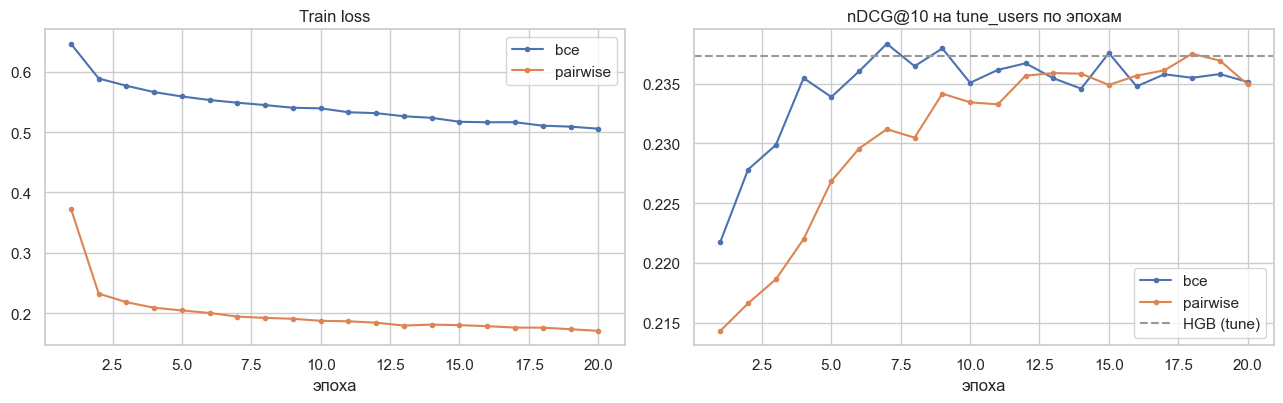

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for loss, r in nn_rankers.items():
    h = pd.DataFrame(r.history)
    axes[0].plot(h["epoch"], h["train_loss"], marker="o", ms=3, label=loss)
    axes[1].plot(h["epoch"], h["val_ndcg@10"], marker="o", ms=3, label=loss)
axes[1].axhline(mean_ndcg(tune_pool, best_ranker.score(tune_pool), ds), ls="--", c=GRAY, label="HGB (tune)")
axes[0].set_title("Train loss"); axes[0].set_xlabel("эпоха"); axes[0].legend()
axes[1].set_title("nDCG@10 на tune_users по эпохам"); axes[1].set_xlabel("эпоха"); axes[1].legend()
plt.tight_layout(); plt.show()

### 5.1 Интеграция в гибридную систему

Нейросеть встраивается в ту же архитектуру тремя способами, и все три оцениваются на `eval_users`:
1. как **самостоятельный ранжировщик** пула (вместо бустинга);
2. как **ансамбль с бустингом**: усреднение рангов внутри пользователя (`RankAverage`). Ранги, а не
   вероятности, потому что у pairwise-сети выход не откалиброван;
3. ансамбль + **MMR** как финальная конфигурация сервиса.

In [31]:
t = time.time()
nn_best = nn_rankers["bce"] if max(h["val_ndcg@10"] for h in nn_rankers["bce"].history) >= \
    max(h["val_ndcg@10"] for h in nn_rankers["pairwise"].history) else nn_rankers["pairwise"]
ensemble = RankAverage({"hgb": best_ranker, "nn": nn_best})
nn_hybrids = {
    "Hybrid: NN ranker (bce)": PoolRecommender(gen, nn_rankers["bce"], pools=pools_eval),
    "Hybrid: NN ranker (pairwise)": PoolRecommender(gen, nn_rankers["pairwise"], pools=pools_eval),
    "Hybrid: HGB + NN ensemble": PoolRecommender(gen, ensemble, pools=pools_eval),
    "Final: HGB + NN + MMR": PoolRecommender(gen, ensemble, pools=pools_eval, reranker=final_reranker),
}
for name, rec in nn_hybrids.items():
    ev.evaluate(name, rec)
print(f"{time.time() - t:.0f}s")
summary = ev.summary(content_model=models["content"])
cmp_rows = ["pure_svd", "Hybrid: HW (PureSVD+Content)", "Hybrid: blend by segment", "Hybrid: HGB all features",
            "Hybrid: NN ranker (bce)", "Hybrid: NN ranker (pairwise)", "Hybrid: HGB + NN ensemble", "Hybrid: HGB + MMR", "Final: HGB + NN + MMR"]
summary.loc[cmp_rows].style.format("{:.4f}").background_gradient(subset=metric_columns(cfg.k_list), cmap="Greens")

Hybrid: NN ranker (bce)          P@10=0.0853  R@10=0.2772  nDCG@10=0.2347


Hybrid: NN ranker (pairwise)     P@10=0.0851  R@10=0.2755  nDCG@10=0.2339


Hybrid: HGB + NN ensemble        P@10=0.0866  R@10=0.2777  nDCG@10=0.2362


Final: HGB + NN + MMR            P@10=0.0869  R@10=0.2791  nDCG@10=0.2357
109s


,Precision@5,Recall@5,nDCG@5,Precision@10,Recall@10,nDCG@10,Coverage,Personalization,ILD
model,,,,,,,,,
pure_svd,0.0951,0.1387,0.1511,0.0684,0.1930,0.1625,0.5614,0.9979,0.7093
Hybrid: HW (PureSVD+Content),0.1010,0.1617,0.1681,0.0726,0.2219,0.1818,0.7259,0.9983,0.6504
Hybrid: blend by segment,0.1038,0.1700,0.1788,0.0742,0.2267,0.1912,0.7494,0.9980,0.6488
Hybrid: HGB all features,0.1242,0.2145,0.2197,0.0861,0.2755,0.2327,0.7270,0.9982,0.7359
Hybrid: NN ranker (bce),0.1233,0.2149,0.2213,0.0853,0.2772,0.2347,0.7071,0.9973,0.7310
Hybrid: NN ranker (pairwise),0.1229,0.2145,0.2209,0.0851,0.2755,0.2339,0.7247,0.9979,0.7335
Hybrid: HGB + NN ensemble,0.1251,0.2160,0.2232,0.0866,0.2777,0.2362,0.7125,0.9980,0.7322
Hybrid: HGB + MMR,0.1229,0.2121,0.2185,0.0859,0.2730,0.2318,0.7403,0.9982,0.7735
Final: HGB + NN + MMR,0.1238,0.2144,0.2210,0.0869,0.2791,0.2357,0.7169,0.9980,0.7443


In [32]:
# Нейросеть против бустинга по сегментам и парный тест
seg_nn = ev.by_segment("nDCG@10", models=["pure_svd", "Hybrid: HGB all features", "Hybrid: NN ranker (bce)",
                                           "Hybrid: NN ranker (pairwise)", "Hybrid: HGB + NN ensemble"])
display(seg_nn.style.format("{:.4f}").background_gradient(axis=0, cmap="Greens"))
pd.DataFrame({
    "NN (bce) − HGB": ev.paired_diff("Hybrid: NN ranker (bce)", "Hybrid: HGB all features"),
    "NN (pairwise) − HGB": ev.paired_diff("Hybrid: NN ranker (pairwise)", "Hybrid: HGB all features"),
    "Ensemble − HGB": ev.paired_diff("Hybrid: HGB + NN ensemble", "Hybrid: HGB all features"),
    "Ensemble − NN (bce)": ev.paired_diff("Hybrid: HGB + NN ensemble", "Hybrid: NN ranker (bce)"),
}).T.round(4)

segment,холодные (≤5),средние (6-20),активные (>20)
model,,,
pure_svd,0.0964,0.1490,0.2480
Hybrid: HGB all features,0.1996,0.2179,0.2879
Hybrid: NN ranker (bce),0.2037,0.2213,0.2855
Hybrid: NN ranker (pairwise),0.1992,0.2222,0.2857
Hybrid: HGB + NN ensemble,0.2019,0.2218,0.2922


,mean diff,CI low,CI high,A better,A worse
NN (bce) − HGB,0.0020,-0.0024,0.0061,0.1887,0.1897
NN (pairwise) − HGB,0.0011,-0.0033,0.0054,0.1880,0.1897
Ensemble − HGB,0.0035,0.0010,0.0062,0.1793,0.1350
Ensemble − NN (bce),0.0015,-0.0012,0.0045,0.1760,0.1343


In [33]:
# Цена: время обучения и инференса (на 1000 пользователей пула eval)
import timeit
sub = eval_pool[eval_pool["user_id"].isin(ds.eval_users[:1000])]
rows = []
for name, r in [("HGB", best_ranker), ("NN (bce)", nn_rankers["bce"]), ("NN (pairwise)", nn_rankers["pairwise"]), ("LogReg", rankers["LogReg: все признаки"])]:
    dt = timeit.timeit(lambda: r.score(sub), number=3) / 3
    rows.append({"ранжировщик": name, "инференс, мс / 1000 пользователей": dt * 1000,
                 "строк": len(sub), "nDCG@10 eval": mean_ndcg(eval_pool, r.score(eval_pool), ds)})
pd.DataFrame(rows).set_index("ранжировщик").round(4)

,"инференс, мс / 1000 пользователей",строк,nDCG@10 eval
ранжировщик,,,
HGB,868.2967,184015,0.2327
NN (bce),84.4335,184015,0.2347
NN (pairwise),83.5504,184015,0.2339
LogReg,75.8306,184015,0.2125


**Нейросеть против классики: что видно.**
- На одинаковых признаках MLP и градиентный бустинг дают **практически одинаковое качество**
  (nDCG@10 ≈ 0.233–0.235), парная разница между ними в пределах доверительного интервала. Это
  ожидаемо для табличных данных с ~80 плотными признаками и ~10 тыс. положительных примеров:
  преимущества нейросетей (представления, обучение на сырых последовательностях) здесь не задействованы.
- **Pairwise-обучение** догоняет pointwise только к 15–20 эпохе: оно оптимизирует более близкую к nDCG
  цель, но видит меньше информации за эпоху (только пары внутри пользователя).
- **Ансамбль** бустинга и сети даёт небольшой, но устойчивый прирост: модели ошибаются по-разному,
  усреднение рангов это сглаживает.
- Нейросеть обучается сопоставимое время (десятки секунд на CPU), в инференсе быстрее бустинга, а в
  ансамбле стоит дополнительных миллисекунд. Главное её практическое преимущество другое: её можно
  дообучать на потоке новых данных и расширять входами, которые бустинг не примет (эмбеддинги
  текста описаний, последовательность чтения). В нашей постановке это задел, а не реализованный выигрыш.

## Этап 6. Итоговое сравнение и выводы

### 6.1 Все модели на одной шкале

,Precision@5,Recall@5,nDCG@5,Precision@10,Recall@10,nDCG@10,Coverage,Personalization,ILD
model,,,,,,,,,
popularity,0.0007,0.0010,0.0008,0.0006,0.0019,0.0011,0.0016,0.0039,0.7093
funk_svd,0.0004,0.0003,0.0005,0.0005,0.0010,0.0008,0.0020,0.1085,0.6437
content,0.0639,0.1254,0.1168,0.0454,0.1680,0.1293,0.6893,0.9971,0.5799
itemcf,0.0797,0.1230,0.1349,0.0524,0.1486,0.1372,0.8015,0.9912,0.7947
pure_svd,0.0951,0.1387,0.1511,0.0684,0.1930,0.1625,0.5614,0.9979,0.7093
Hybrid: HW (PureSVD+Content),0.1010,0.1617,0.1681,0.0726,0.2219,0.1818,0.7259,0.9983,0.6504
Hybrid: blend global,0.1036,0.1685,0.1775,0.0733,0.2225,0.1888,0.7088,0.9980,0.6449
Hybrid: blend by segment,0.1038,0.1700,0.1788,0.0742,0.2267,0.1912,0.7494,0.9980,0.6488
Hybrid: HGB scores only,0.0995,0.1677,0.1743,0.0721,0.2275,0.1893,0.7336,0.9980,0.7112


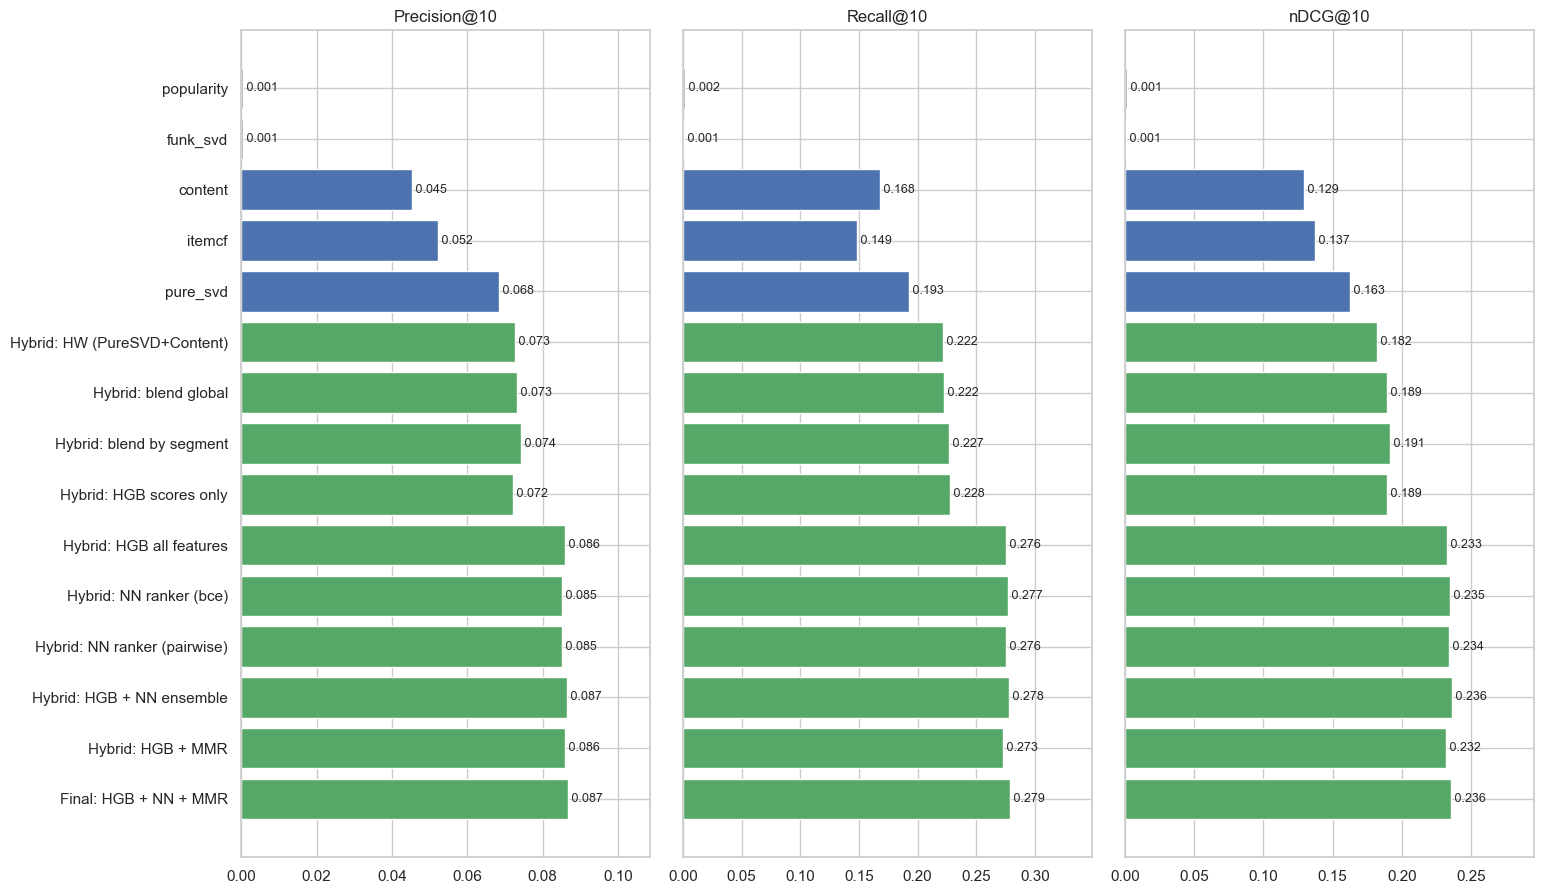

In [34]:
order = ["popularity", "funk_svd", "content", "itemcf", "pure_svd",
         "Hybrid: HW (PureSVD+Content)", "Hybrid: blend global", "Hybrid: blend by segment",
         "Hybrid: HGB scores only", "Hybrid: HGB all features", "Hybrid: NN ranker (bce)", "Hybrid: NN ranker (pairwise)",
         "Hybrid: HGB + NN ensemble", "Hybrid: HGB + MMR", "Final: HGB + NN + MMR"]
final_table = summary.loc[order]
final_table.to_csv(cfg.artifacts_path / "final_metrics.csv")
display(final_table.style.format("{:.4f}").background_gradient(subset=metric_columns(cfg.k_list), cmap="Greens"))
plot_metrics(final_table, highlight=("Hybrid", "Final"))

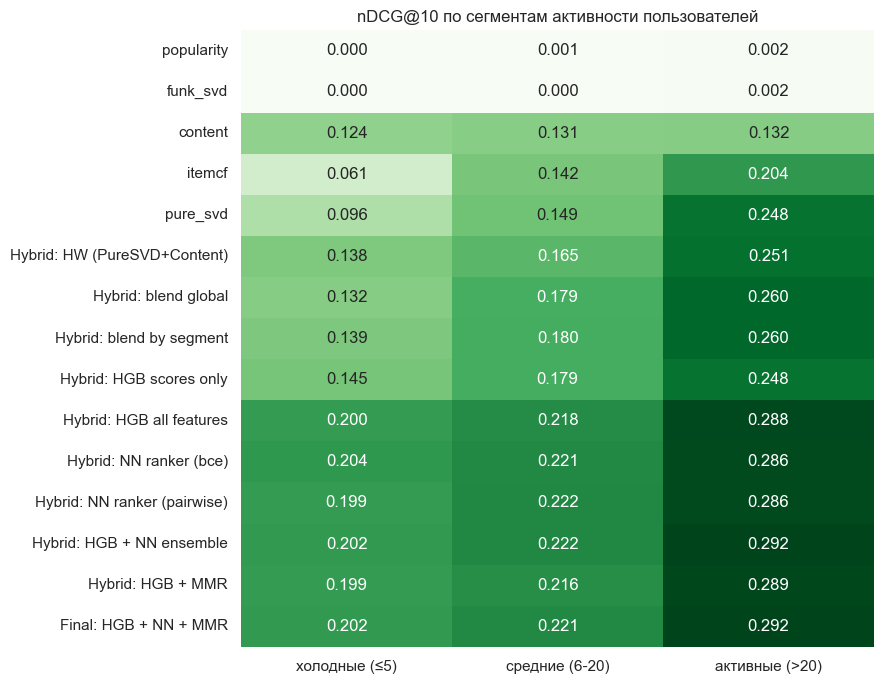

,прирост nDCG@10 финальной системы над лучшей одиночной моделью
segment,
холодные (≤5),0.623
средние (6-20),0.482
активные (>20),0.177


In [35]:
seg_all = ev.by_segment("nDCG@10", models=order)
fig, ax = plt.subplots(figsize=(9, 7))
sns.heatmap(seg_all, annot=True, fmt=".3f", cmap="Greens", ax=ax, cbar=False)
ax.set_title("nDCG@10 по сегментам активности пользователей"); ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

# Относительный прирост финальной системы над лучшей одиночной моделью в каждом сегменте
gain = (seg_all.loc["Final: HGB + NN + MMR"] / seg_all.loc[["content", "itemcf", "pure_svd"]].max() - 1)
gain.rename("прирост nDCG@10 финальной системы над лучшей одиночной моделью").round(3).to_frame()

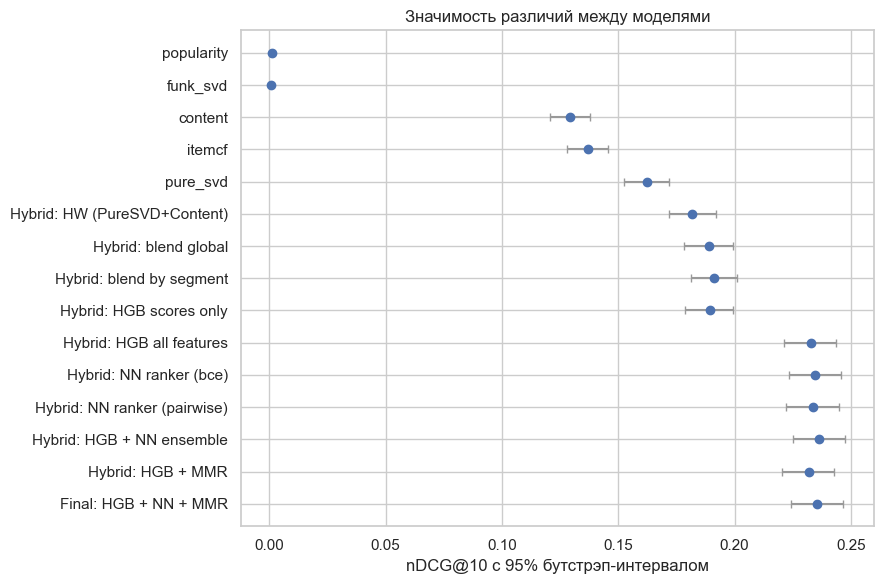

In [36]:
ci = ev.ci_table("nDCG@10").loc[order]
fig, ax = plt.subplots(figsize=(9, 6))
mid = final_table["nDCG@10"]
ax.errorbar(mid.values, range(len(mid)), xerr=[mid.values - ci.iloc[:, 0].values, ci.iloc[:, 1].values - mid.values],
            fmt="o", color=BLUE, ecolor=GRAY, capsize=3)
ax.set_yticks(range(len(mid))); ax.set_yticklabels(mid.index); ax.invert_yaxis()
ax.set_xlabel("nDCG@10 с 95% бутстрэп-интервалом"); ax.set_title("Значимость различий между моделями")
plt.tight_layout(); plt.show()

### 6.2 Сильные и слабые стороны методов

| Метод | Сильные стороны | Слабые стороны | Когда использовать |
|---|---|---|---|
| **Popularity** | Простота; работает без истории; хорошие кандидаты «по умолчанию» | Нет персонализации; на этих данных (≈100 оценок на книгу) на уровне Random | Только как fallback для совсем новых пользователей и как признак |
| **Content (TF-IDF)** | Работает с 1–2 оценками и для новых книг; объяснимость; лучший источник кандидатов для холодных | «Больше того же»: низкое разнообразие; зависит от качества тегов; не растёт с активностью | Холодный старт, онбординг, новые книги, слой разнообразия |
| **Item-CF** | Находит «читают те же люди»; объяснимость; ловит связи, которых нет в тегах | Холодный старт; дорогой инференс (O(n_u × I)); смещение к популярному | Признак и источник кандидатов для средних и активных |
| **FunkSVD** | Лучший RMSE; учитывает смещения | Для Top-N бесполезен: решает не ту задачу; всем один список | Как признак «качества книги» (b_i), не как рекомендатель |
| **PureSVD** | Лучшая одиночная модель Top-N; быстрый инференс; главный источник кандидатов | Холодный старт; нужно много факторов; одна и та же выдача для похожих историй | Основа пула кандидатов для всех, кто оставил хотя бы несколько оценок |
| **Смешивание скоров** | Прозрачно, 5 параметров, легко объяснить и контролировать; +5% к PureSVD | Потолок невысокий: не использует ничего, кроме скоров; веса надо подбирать на отложенных данных | Когда нужен простой и надёжный гибрид без обучения второго уровня |
| **Бустинг на признаках** | +43% к PureSVD; автоматически учитывает сегменты и контекст; устойчив, interpretable через permutation importance | Нужен пул кандидатов и разметка; признаки надо поддерживать; качество ограничено recall пула | Основной ранжировщик |
| **Нейросетевой ранжировщик** | Качество бустинга; быстрый инференс; дообучение и расширяемость входов (тексты, последовательности) | На табличных признаках выигрыша нет; больше гиперпараметров; менее прозрачен | В ансамбле с бустингом; когда появятся эмбеддинги описаний или событийный поток |
| **MMR** | Управляемый компромисс точности и разнообразия; убирает «пять книг одной серии» | Снижает nDCG; нужна матрица близости; параметр подбирается вручную | Финальный слой перед показом пользователю |

### 6.3 Выводы и рекомендации

1. **Главный результат: расширенные признаки дают больше, чем любое смешивание моделей.** Бустинг,
   который видит только скоры пяти моделей, равен лучшему смешиванию (nDCG@10 ≈ 0.19). Признаки
   взаимодействия добавляют +14%, признаки пользователя и книги ещё +8%. Итоговый ранжировщик (0.233)
   на 43% лучше PureSVD и на 28% лучше гибрида из ДЗ.
2. **Двухуровневая архитектура (кандидаты → ранжирование) ничего не теряет и много даёт.** Гибрид ДЗ,
   пересаженный на пул из ≈185 кандидатов, показывает ту же точность, что и на всех 10 000 книгах, а
   ранжирование становится в 50 раз дешевле. Главное ограничение переносится на recall пула (≈0.45):
   следующий резерв роста именно там (больше кандидатов, новые генераторы вроде ALS/EASE).
3. **Нет одной лучшей базовой модели, и ранжировщик это выучил сам.** Веса по сегментам (Content для
   холодных, PureSVD для активных) воспроизводят вывод ДЗ автоматически, а бустинг делает то же мягче,
   опираясь на активность, жанровый профиль и мейнстримность пользователя как признаки.
4. **Нейросеть на табличных признаках равна бустингу, а не лучше его.** Честный вывод продвинутой части:
   при ~80 плотных признаках и ~10 тыс. положительных примеров MLP и HGB неразличимы по качеству, ансамбль
   даёт небольшой прирост. Нейросеть оправдана как платформа для будущих входов (текстовые эмбеддинги,
   последовательности чтения), а не как замена бустинга сегодня.
5. **Разнообразие надо покупать осознанно.** MMR с λ ≈ 0.8–0.9 добавляет заметное разнообразие и
   покрытие каталога при потере nDCG около 1%. Это настраиваемая ручка продукта, а не свойство модели.

**Что выбрать для сервиса.** Пул кандидатов от PureSVD + Content + Item-CF (Popularity и FunkSVD как
источники кандидатов отключить, их скоры оставить признаками), ранжирование ансамблем бустинга и
нейросети, MMR со штрафом за автора сверху, популярное и онбординг для холодного старта.

### 6.4 Ограничения
- Случайное разбиение вместо временного: в данных нет времени оценок, оценки немного оптимистичны.
- Непрочитанная книга считается нерелевантной, часть «ошибок» на самом деле хорошие рекомендации.
- Выборка оценок обрезана (≈100 на книгу), эффекты популярности слабее, чем в реальном сервисе.
- Ранжировщики обучены на тестовых метках `fit_users`; в продакшене это были бы логи показов.

## Этап 7. Сквозной пайплайн

Весь процесс собран в [`pipeline.py`](src/bookrec/pipeline.py) и запускается одной командой
[`run_pipeline.py`](run_pipeline.py):

```
загрузка данных → предобработка и split → базовые модели → признаки → пулы кандидатов
→ веса смешивания, бустинг, нейросеть, подбор MMR → оценка на eval_users → сервис рекомендаций → отчёт
```

- Каждый этап кэширует результат в `--artifacts-dir`, повторный запуск занимает минуты.
- **Новые данные** того же формата (четыре CSV): `python3 run_pipeline.py --data-dir <папка> --artifacts-dir <новая папка>`.
  Все seed, пороги и размеры выборок задаются в `Config` и флагами CLI.
- На выходе: `metrics_summary.csv`, `metrics_by_segment.csv`, `plots/*.png`, `sample_recommendations.csv`,
  `report.md`, а также сохранённые модели и ранжировщики.

Ниже пайплайн запускается в быстром режиме (`--quick`: уменьшенные выборки пользователей, 8 эпох сети)
в отдельную папку `artifacts_quick`, чтобы показать весь процесс целиком.

In [37]:
!python3 run_pipeline.py --quick --artifacts-dir artifacts_quick


=== 1. Загрузка и предобработка данных ===


    ratings=979,478, users=53,424, books=10,000, train=784,517, test=194,961, users_with_relevant_test=37,968, eval_users=800, tune_users=500, fit_users=1,500
    [data] 2.5s

=== 2. Базовые модели (Popularity, Content, Item-CF, FunkSVD, PureSVD) ===


    [models] 0.1s

=== 3. Признаки пользователей и книг ===


    book: (10000, 29), user: (53424, 30)
    [features] 2.2s

=== 4. Пулы кандидатов и признаки взаимодействий (fit / tune / eval) ===


    train (276762, 82), tune (92106, 82), eval (147563, 82)
    [pools] 0.3s

=== 5. Гибрид: веса смешивания, бустинг, нейросеть, MMR ===
    blend weights: seg0: content=0.60, funk_svd=0.14, pure_svd=0.23; seg1: content=0.67, itemcf=0.11, pure_svd=0.19; seg2: content=0.64, pure_svd=0.27


    HGB tune nDCG@10 = 0.2226


    NN  tune nDCG@10 = 0.2276
    MMR: λ=0.9, штраф за автора=0.0
    [hybrid] 2.2s

=== 6. Оценка на eval_users ===


                              Precision@10  Recall@10  nDCG@10  Coverage     ILD
model                                                                           
popularity                          0.0004     0.0016   0.0006    0.0014  0.7098
content                             0.0456     0.1740   0.1314    0.4004  0.5946
itemcf                              0.0521     0.1482   0.1353    0.4532  0.7989
funk_svd                            0.0002     0.0003   0.0002    0.0020  0.6399
pure_svd                            0.0658     0.1834   0.1592    0.3516  0.7125
Hybrid: HW (PureSVD+Content)        0.0711     0.2178   0.1785    0.4283  0.6536
Hybrid: blend by segment            0.0686     0.2140   0.1847    0.4294  0.6495
Hybrid: HGB all features            0.0809     0.2691   0.2296    0.4301  0.7434
Hybrid: NN ranker                   0.0791     0.2710   0.2271    0.4108  0.7223
Hybrid: HGB + NN                    0.0809     0.2694   0.2308    0.4187  0.7309
Final: ranker + MMR         

    [evaluate] 51.7s

=== 7. Сервис рекомендаций и примеры выдачи ===


                           case                          source                                                             title
                        user 41                   hybrid ranker                             The Lost City of Faar (Pendragon, #2)
                        user 41                   hybrid ranker               The Good, the Bad, and the Undead (The Hollows, #2)
                        user 41                   hybrid ranker                           For a Few Demons More (The Hollows, #5)
onboarding: Hunger Games + Dune onboarding (content + pure_svd)                              Catching Fire (The Hunger Games, #2)
onboarding: Hunger Games + Dune onboarding (content + pure_svd)                                 Mockingjay (The Hunger Games, #3)
onboarding: Hunger Games + Dune onboarding (content + pure_svd)                             Heretics of Dune (Dune Chronicles #5)
                       new user              popular (bayesian) The Authoritative Calvin a

,Precision@10,Recall@10,nDCG@10,Coverage,ILD
model,,,,,
popularity,0.0004,0.0016,0.0006,0.0014,0.7098
content,0.0456,0.1740,0.1314,0.4004,0.5946
itemcf,0.0521,0.1482,0.1353,0.4532,0.7989
funk_svd,0.0002,0.0003,0.0002,0.0020,0.6399
pure_svd,0.0658,0.1834,0.1592,0.3516,0.7125
Hybrid: HW (PureSVD+Content),0.0711,0.2178,0.1785,0.4283,0.6536
Hybrid: blend by segment,0.0686,0.2140,0.1847,0.4294,0.6495
Hybrid: HGB all features,0.0809,0.2691,0.2296,0.4301,0.7434
Hybrid: NN ranker,0.0791,0.2710,0.2271,0.4108,0.7223


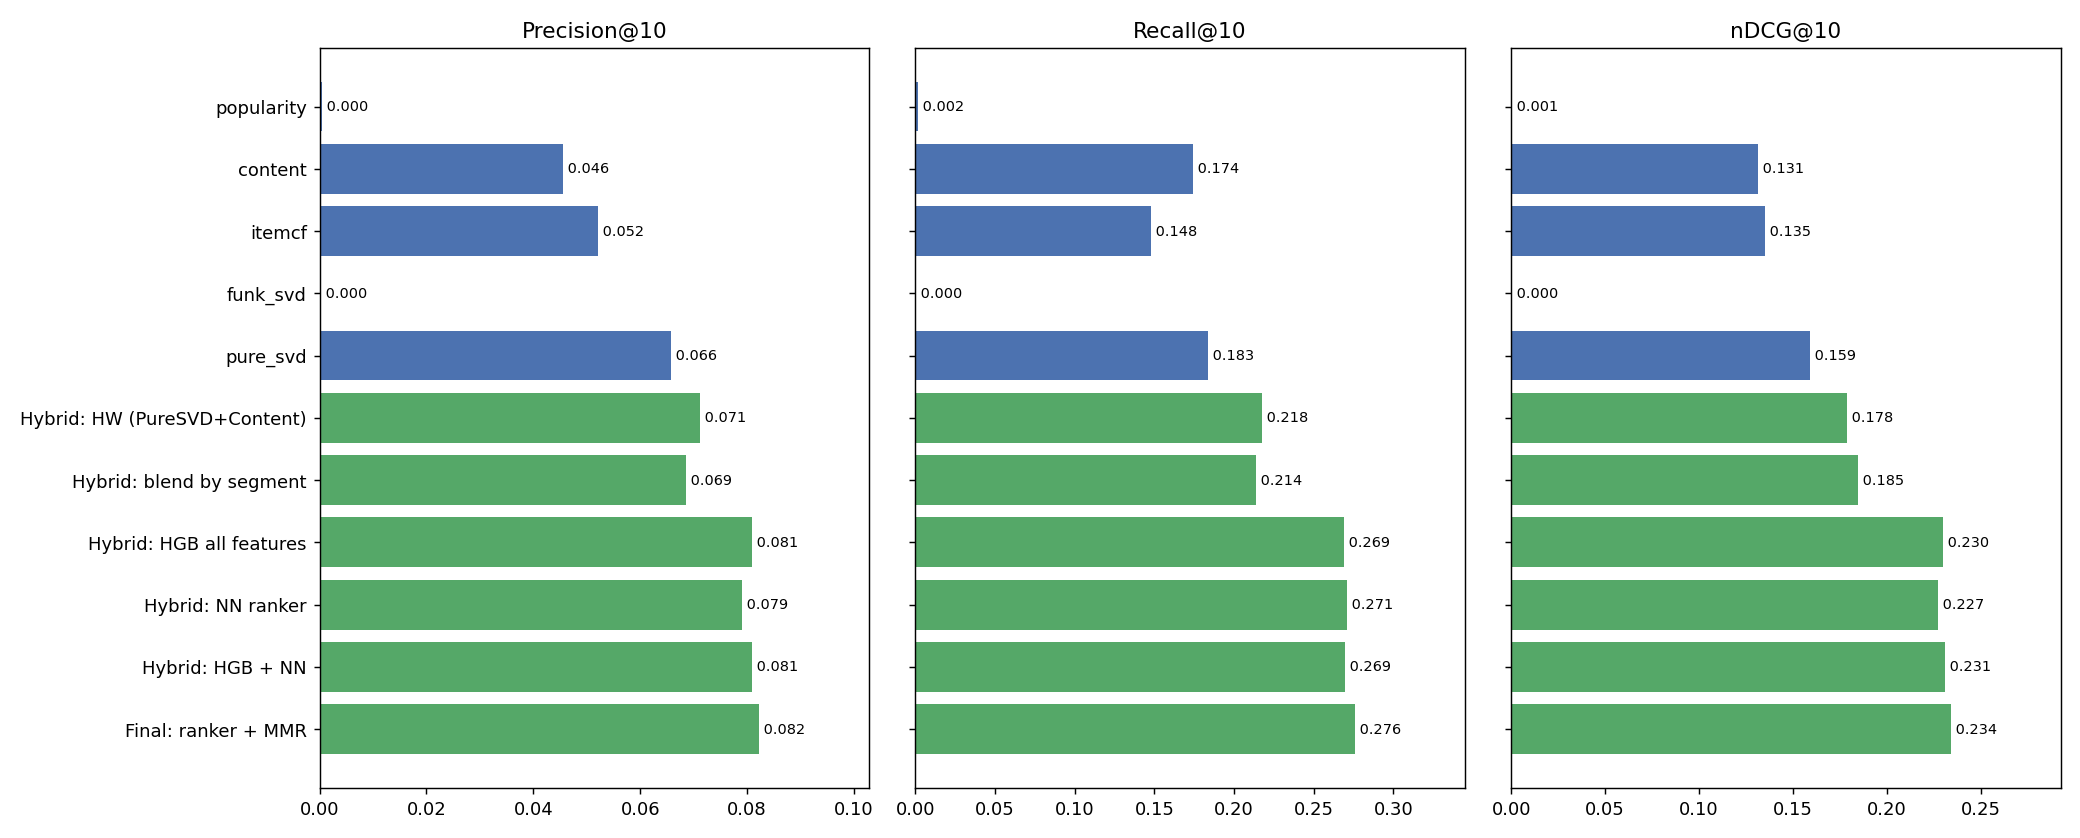

,case,source,title,authors
0,user 41,hybrid ranker,"The Lost City of Faar (Pendragon, #2)",D.J. MacHale
1,user 41,hybrid ranker,"The Good, the Bad, and the Undead (The Hollows...",Kim Harrison
2,user 41,hybrid ranker,"For a Few Demons More (The Hollows, #5)",Kim Harrison
3,user 41,hybrid ranker,"The Reality Bug (Pendragon, #4)",D.J. MacHale
10,onboarding: Hunger Games + Dune,onboarding (content + pure_svd),"Catching Fire (The Hunger Games, #2)",Suzanne Collins
11,onboarding: Hunger Games + Dune,onboarding (content + pure_svd),"Mockingjay (The Hunger Games, #3)",Suzanne Collins
12,onboarding: Hunger Games + Dune,onboarding (content + pure_svd),Heretics of Dune (Dune Chronicles #5),Frank Herbert
13,onboarding: Hunger Games + Dune,onboarding (content + pure_svd),Dune Messiah (Dune Chronicles #2),Frank Herbert
20,new user,popular (bayesian),The Authoritative Calvin and Hobbes: A Calvin ...,Bill Watterson
21,new user,popular (bayesian),It's a Magical World: A Calvin and Hobbes Coll...,Bill Watterson


In [38]:
from IPython.display import Markdown, Image
display(pd.read_csv("artifacts_quick/metrics_summary.csv", index_col=0)[["Precision@10", "Recall@10", "nDCG@10", "Coverage", "ILD"]].round(4))
display(Image("artifacts_quick/plots/metrics.png", width=900))
pd.read_csv("artifacts_quick/sample_recommendations.csv").groupby("case").head(4)[["case", "source", "title", "authors"]]

Быстрый режим использует меньше пользователей, поэтому абсолютные числа немного отличаются от основной
части, но порядок моделей тот же: финальный гибрид заметно впереди базовых моделей и гибрида из ДЗ.
Полный прогон (`python3 run_pipeline.py`) воспроизводит все таблицы этого ноутбука.